In [5]:
import os, re, random, copy, time, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); cv2.setRNGSeed(SEED)

CFG = {
    "modality": "T1",
    "img_size": 224,
    "val_fraction": 0.15,      # carved out of the official train split
    "n_tissue_clusters": 3,    # intensity classes inside the brain mask
    "debug": False,            # True = tiny subset + 1-2 epochs for a dry run
    "debug_per_class": 30,
    "seg_encoder": "convnext_tiny",
    "seg_epochs": 25,
    "cls_models": ["convnext_tiny", "swin_tiny_patch4_window7_224"],
    "cls_epochs": 15,
    "batch_size": 32,
    "pretrained": True,        # needs Internet ON in Kaggle; falls back to random init if download fails
}
IMG = CFG["img_size"]
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

# **load the dataset index**

In [6]:
def find_dataset_root():
    for base in ["/kaggle/input", "."]:
        if Path(base).exists():
            hits = [p for p in Path(base).rglob("Dataset_myelination") if p.is_dir()]
            if hits:
                return hits[0]
    raise FileNotFoundError("Dataset_myelination not found. Add buraktaci/neonatal-brain-development-mri to the notebook.")

ROOT = find_dataset_root()
print("Dataset root:", ROOT)

def age_to_months(s):
    s = s.lower().strip()
    nums = [float(x) for x in re.findall(r"\d+\.?\d*", s)]
    if not nums:
        return np.nan
    if "day" in s:
        return (sum(nums) / len(nums)) / 30.0
    return nums[0]

records = []
for p in ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in (".png", ".jpg", ".jpeg"):
        q = p.parts
        records.append({"path": str(p), "modality": q[-5], "sex": q[-4].lower(),
                        "split": q[-3].lower(), "age_class": q[-2]})
df = pd.DataFrame(records)
df = df[df["modality"].str.upper() == CFG["modality"].upper()].copy()
df["age_months"] = df["age_class"].apply(age_to_months)

class_order = df.groupby("age_class")["age_months"].first().sort_values().index.tolist()
class_to_idx = {c: i for i, c in enumerate(class_order)}
df["label"] = df["age_class"].map(class_to_idx)
n_classes = len(class_order)

if CFG["debug"]:
    df = df.groupby("age_class").head(CFG["debug_per_class"])
df = df.reset_index(drop=True)

print("Images:", len(df), "| classes:", n_classes)
print("Class order (young -> old):", class_order)
print(df["split"].value_counts().to_string())
print(pd.crosstab(df["age_class"], df["split"]).loc[class_order])

Dataset root: /kaggle/input/datasets/buraktaci/neonatal-brain-development-mri/Dataset_myelination
Images: 15908 | classes: 14
Class order (young -> old): ['0-10 Day', '11-20 Day', '21-30 Day', '2 Month', '3 Month', '4 Month', '5 Month', '6 Month', '7 Month', '8 Month', '9 Month', '10 Month', '11 Month', '12 Month']
split
train    12728
test      3180
split      test  train
age_class             
0-10 Day    244    974
11-20 Day   250   1001
21-30 Day   240    963
2 Month     211    841
3 Month     204    817
4 Month     229    917
5 Month     217    869
6 Month     255   1019
7 Month     220    883
8 Month     235    941
9 Month     201    805
10 Month    211    844
11 Month    231    926
12 Month    232    928


# **Preprocessing**

Cached images: (15908, 224, 224) uint8 (608s)


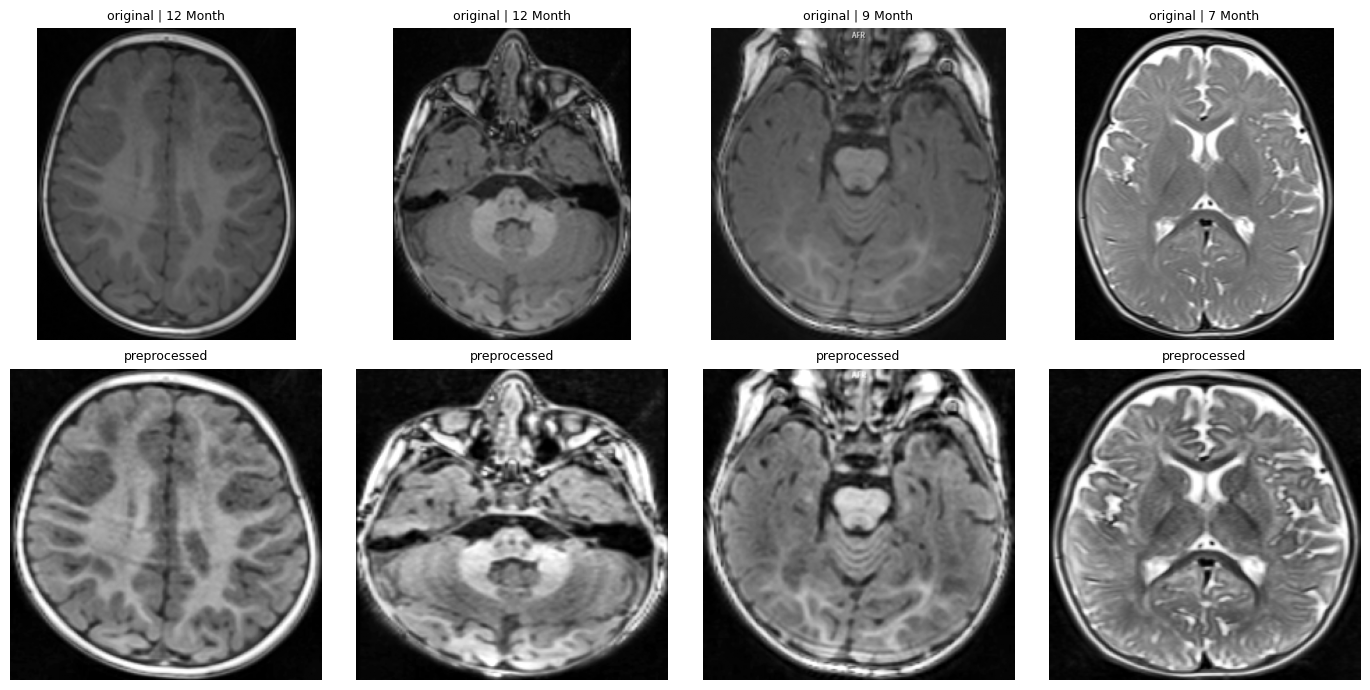

In [7]:
def preprocess(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Unable to read {path}")
    img = cv2.GaussianBlur(img, (3, 3), 0)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img = clahe.apply(img)
    img = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA).astype(np.float32)
    lo, hi = np.percentile(img, (1, 99))
    img = np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)
    return (img * 255).astype(np.uint8)

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    X = np.stack(list(ex.map(preprocess, df["path"].tolist())))
print("Cached images:", X.shape, X.dtype, f"({time.time()-t0:.0f}s)")

idx = np.random.choice(len(df), 4, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for k, i in enumerate(idx):
    ax[0, k].imshow(cv2.imread(df.path[i], 0), cmap="gray"); ax[0, k].set_title(f"original | {df.age_class[i]}", fontsize=9)
    ax[1, k].imshow(X[i], cmap="gray"); ax[1, k].set_title("preprocessed", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

#  **pseudo-labels for segmentation**

Brain-mask area fraction: mean 0.86, min 0.06, max 0.98
Suspicious masks (<10% or >95% of image): 1368


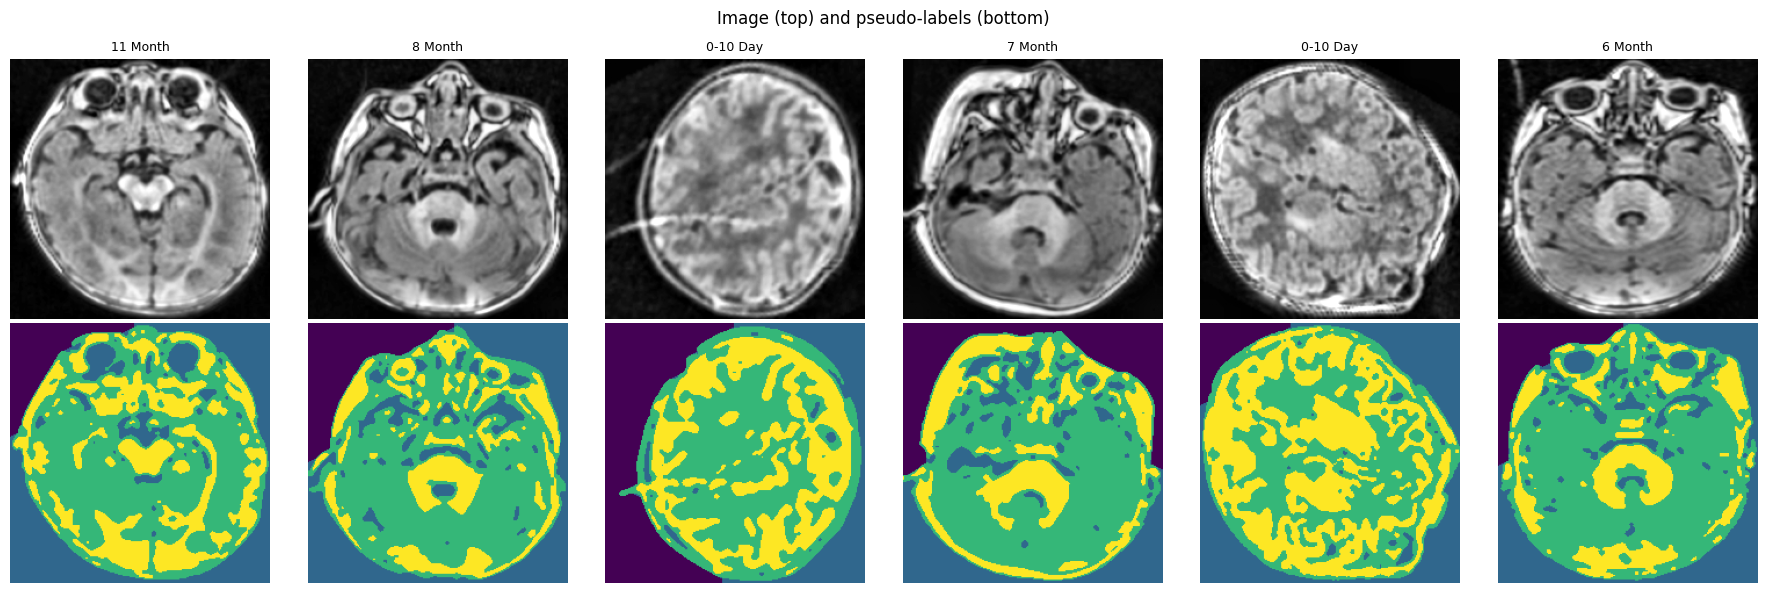

In [8]:
def brain_mask(img):
    blur = cv2.GaussianBlur(img, (5, 5), 0)
    _, m = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k, iterations=1)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k, iterations=3)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n > 1:
        keep = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        m = np.where(lab == keep, 255, 0).astype(np.uint8)
    if m[0, 0] == 0:                       # fill interior holes (ventricles etc.)
        ff = m.copy()
        cv2.floodFill(ff, np.zeros((m.shape[0] + 2, m.shape[1] + 2), np.uint8), (0, 0), 255)
        m = m | cv2.bitwise_not(ff)
    return (m > 0).astype(np.uint8)

def tissue_labels(img, mask, k):
    lab = np.zeros(img.shape, np.uint8)
    px = img[mask > 0].reshape(-1, 1).astype(np.float32)
    if px.shape[0] < 500:
        return lab
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
    _, assign, centers = cv2.kmeans(px, k, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    order = np.argsort(centers.ravel())
    remap = np.zeros(k, np.uint8)
    remap[order] = np.arange(1, k + 1)
    lab[mask > 0] = remap[assign.ravel()]
    lab = cv2.medianBlur(lab, 5)           # smooth speckle
    lab[mask == 0] = 0
    return lab

K = CFG["n_tissue_clusters"]
N_SEG_CLASSES = K + 1
Y = np.zeros_like(X)
frac = np.zeros(len(X))
for i in range(len(X)):
    m = brain_mask(X[i])
    Y[i] = tissue_labels(X[i], m, K)
    frac[i] = m.mean()
print(f"Brain-mask area fraction: mean {frac.mean():.2f}, min {frac.min():.2f}, max {frac.max():.2f}")
print(f"Suspicious masks (<10% or >95% of image): {int(((frac < .1) | (frac > .95)).sum())}")

idx = np.random.choice(len(df), 6, replace=False)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for k, i in enumerate(idx):
    ax[0, k].imshow(X[i], cmap="gray"); ax[0, k].set_title(df.age_class[i], fontsize=9)
    ax[1, k].imshow(Y[i], cmap="viridis", vmin=0, vmax=K)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.suptitle("Image (top) and pseudo-labels (bottom)"); plt.tight_layout(); plt.show()

In [9]:
for name in ["df", "X", "Y", "K", "N_SEG_CLASSES", "train_idx", "val_idx", "test_idx"]:
    print(name, "OK" if name in globals() else "MISSING")

df OK
X OK
Y OK
K OK
N_SEG_CLASSES OK
train_idx MISSING
val_idx MISSING
test_idx MISSING


In [10]:
from sklearn.model_selection import train_test_split

train_all = df.index[df.split == "train"].to_numpy()
test_idx = df.index[df.split == "test"].to_numpy()
assert len(train_all) and len(test_idx), f"Unexpected split names: {df.split.unique()}"

train_idx, val_idx = train_test_split(
    train_all, test_size=CFG["val_fraction"], random_state=SEED,
    stratify=df["label"].to_numpy()[train_all])
print("train / val / test:", len(train_idx), len(val_idx), len(test_idx))

train / val / test: 10818 1910 3180


segmentation model (U-Net with a ConvNeXt encoder) and training

In [11]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
torch.manual_seed(SEED)
print("Device:", device, torch.cuda.get_device_name(0) if AMP else "")

def augment_pair(img, lab=None, p_affine=0.8):
    h, w = img.shape
    if random.random() < 0.5:
        img = img[:, ::-1]
        lab = lab[:, ::-1] if lab is not None else None
    if random.random() < p_affine:
        ang, sc = random.uniform(-10, 10), random.uniform(0.92, 1.08)
        tx, ty = random.uniform(-0.05, 0.05) * w, random.uniform(-0.05, 0.05) * h
        M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, sc)
        M[:, 2] += (tx, ty)
        img = cv2.warpAffine(np.ascontiguousarray(img), M, (w, h), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        if lab is not None:
            lab = cv2.warpAffine(np.ascontiguousarray(lab), M, (w, h), flags=cv2.INTER_NEAREST,
                                 borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    a, b = random.uniform(0.85, 1.15), random.uniform(-0.08, 0.08) * 255
    img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
    return np.ascontiguousarray(img), (np.ascontiguousarray(lab) if lab is not None else None)

class SegDS(Dataset):
    def __init__(self, idx, X, Y, train):
        self.idx, self.X, self.Y, self.train = idx, X, Y, train
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img, lab = self.X[j], self.Y[j]
        if self.train:
            img, lab = augment_pair(img, lab)
        return (torch.from_numpy(img).float().div(255).unsqueeze(0),
                torch.from_numpy(lab).long())

def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, num_workers=2,
                      pin_memory=AMP, drop_last=False)

seg_train_loader = make_loader(SegDS(train_idx, X, Y, True), True)
seg_val_loader = make_loader(SegDS(val_idx, X, Y, False), False)
seg_test_loader = make_loader(SegDS(test_idx, X, Y, False), False)

def conv_block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class TimmUNet(nn.Module):
    def __init__(self, encoder, n_classes, pretrained=True):
        super().__init__()
        try:
            self.enc = timm.create_model(encoder, pretrained=pretrained, features_only=True, in_chans=1)
        except Exception as e:
            print("Pretrained weights unavailable, using random init:", repr(e)[:120])
            self.enc = timm.create_model(encoder, pretrained=False, features_only=True, in_chans=1)
        chs = self.enc.feature_info.channels()
        self.blocks = nn.ModuleList()
        c = chs[-1]
        for skip_c in reversed(chs[:-1]):
            self.blocks.append(conv_block(c + skip_c, skip_c))
            c = skip_c
        self.head = nn.Sequential(nn.Conv2d(c, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.Conv2d(32, n_classes, 1))
    def forward(self, x):
        H, W = x.shape[-2:]
        feats = self.enc((x - 0.45) / 0.225)
        y = feats[-1]
        for blk, skip in zip(self.blocks, reversed(feats[:-1])):
            y = F.interpolate(y, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            y = blk(torch.cat([y, skip], 1))
        y = F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)
        return self.head(y)

def dice_loss(logits, y, n, eps=1e-6):
    p = logits.softmax(1)
    oh = F.one_hot(y, n).permute(0, 3, 1, 2).float()
    inter = (p * oh).sum((0, 2, 3))
    den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()

def seg_loss(logits, y):
    return 0.5 * F.cross_entropy(logits, y) + 0.5 * dice_loss(logits, y, N_SEG_CLASSES)

@torch.no_grad()
def eval_seg(model, loader):
    model.eval()
    tp = np.zeros(N_SEG_CLASSES); fp = np.zeros(N_SEG_CLASSES); fn = np.zeros(N_SEG_CLASSES)
    btp = bfp = bfn = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            pred = model(x).argmax(1)
        for c in range(N_SEG_CLASSES):
            tp[c] += ((pred == c) & (y == c)).sum().item()
            fp[c] += ((pred == c) & (y != c)).sum().item()
            fn[c] += ((pred != c) & (y == c)).sum().item()
        pb, yb = pred > 0, y > 0
        btp += (pb & yb).sum().item(); bfp += (pb & ~yb).sum().item(); bfn += (~pb & yb).sum().item()
    eps = 1e-7
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    return {"dice_per_class": dice, "mean_dice_fg": dice[1:].mean(), "mean_iou_fg": iou[1:].mean(),
            "brain_dice": (2 * btp + eps) / (2 * btp + bfp + bfn + eps)}

def train_segmentation(epochs):
    model = TimmUNet(CFG["seg_encoder"], N_SEG_CLASSES, CFG["pretrained"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    best, best_w, hist = -1, None, []
    for ep in range(epochs):
        model.train(); tl = 0
        for x, y in seg_train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=AMP):
                loss = seg_loss(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()
        sched.step()
        v = eval_seg(model, seg_val_loader)
        hist.append((tl / len(seg_train_loader), v["mean_dice_fg"], v["brain_dice"]))
        if v["mean_dice_fg"] > best:
            best, best_w = v["mean_dice_fg"], copy.deepcopy(model.state_dict())
        print(f"ep {ep+1:02d} | loss {hist[-1][0]:.4f} | val fg-Dice {v['mean_dice_fg']:.4f} | val brain-Dice {v['brain_dice']:.4f}")
    model.load_state_dict(best_w)
    return model, hist

seg_epochs = 2 if CFG["debug"] else CFG["seg_epochs"]
seg_model, seg_hist = train_segmentation(seg_epochs)

Device: cuda Tesla T4


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

ep 01 | loss 0.3820 | val fg-Dice 0.8821 | val brain-Dice 0.9621
ep 02 | loss 0.2296 | val fg-Dice 0.9175 | val brain-Dice 0.9818
ep 03 | loss 0.1887 | val fg-Dice 0.9295 | val brain-Dice 0.9828
ep 04 | loss 0.1627 | val fg-Dice 0.9215 | val brain-Dice 0.9855
ep 05 | loss 0.1492 | val fg-Dice 0.9261 | val brain-Dice 0.9880
ep 06 | loss 0.1382 | val fg-Dice 0.9500 | val brain-Dice 0.9917
ep 07 | loss 0.1292 | val fg-Dice 0.9451 | val brain-Dice 0.9928
ep 08 | loss 0.1236 | val fg-Dice 0.9472 | val brain-Dice 0.9903
ep 09 | loss 0.1179 | val fg-Dice 0.9253 | val brain-Dice 0.9918
ep 10 | loss 0.1112 | val fg-Dice 0.9547 | val brain-Dice 0.9931
ep 11 | loss 0.1069 | val fg-Dice 0.9513 | val brain-Dice 0.9921
ep 12 | loss 0.1031 | val fg-Dice 0.9462 | val brain-Dice 0.9927
ep 13 | loss 0.0972 | val fg-Dice 0.9542 | val brain-Dice 0.9942
ep 14 | loss 0.0936 | val fg-Dice 0.9550 | val brain-Dice 0.9935
ep 15 | loss 0.0906 | val fg-Dice 0.9584 | val brain-Dice 0.9933
ep 16 | loss 0.0872 | val

TEST (against pseudo-labels)
  brain-mask Dice : 0.9953
  mean fg Dice    : 0.9639 | mean fg IoU: 0.9304
  class 0 Dice   : 0.9702
  class 1 Dice   : 0.9640
  class 2 Dice   : 0.9661
  class 3 Dice   : 0.9617


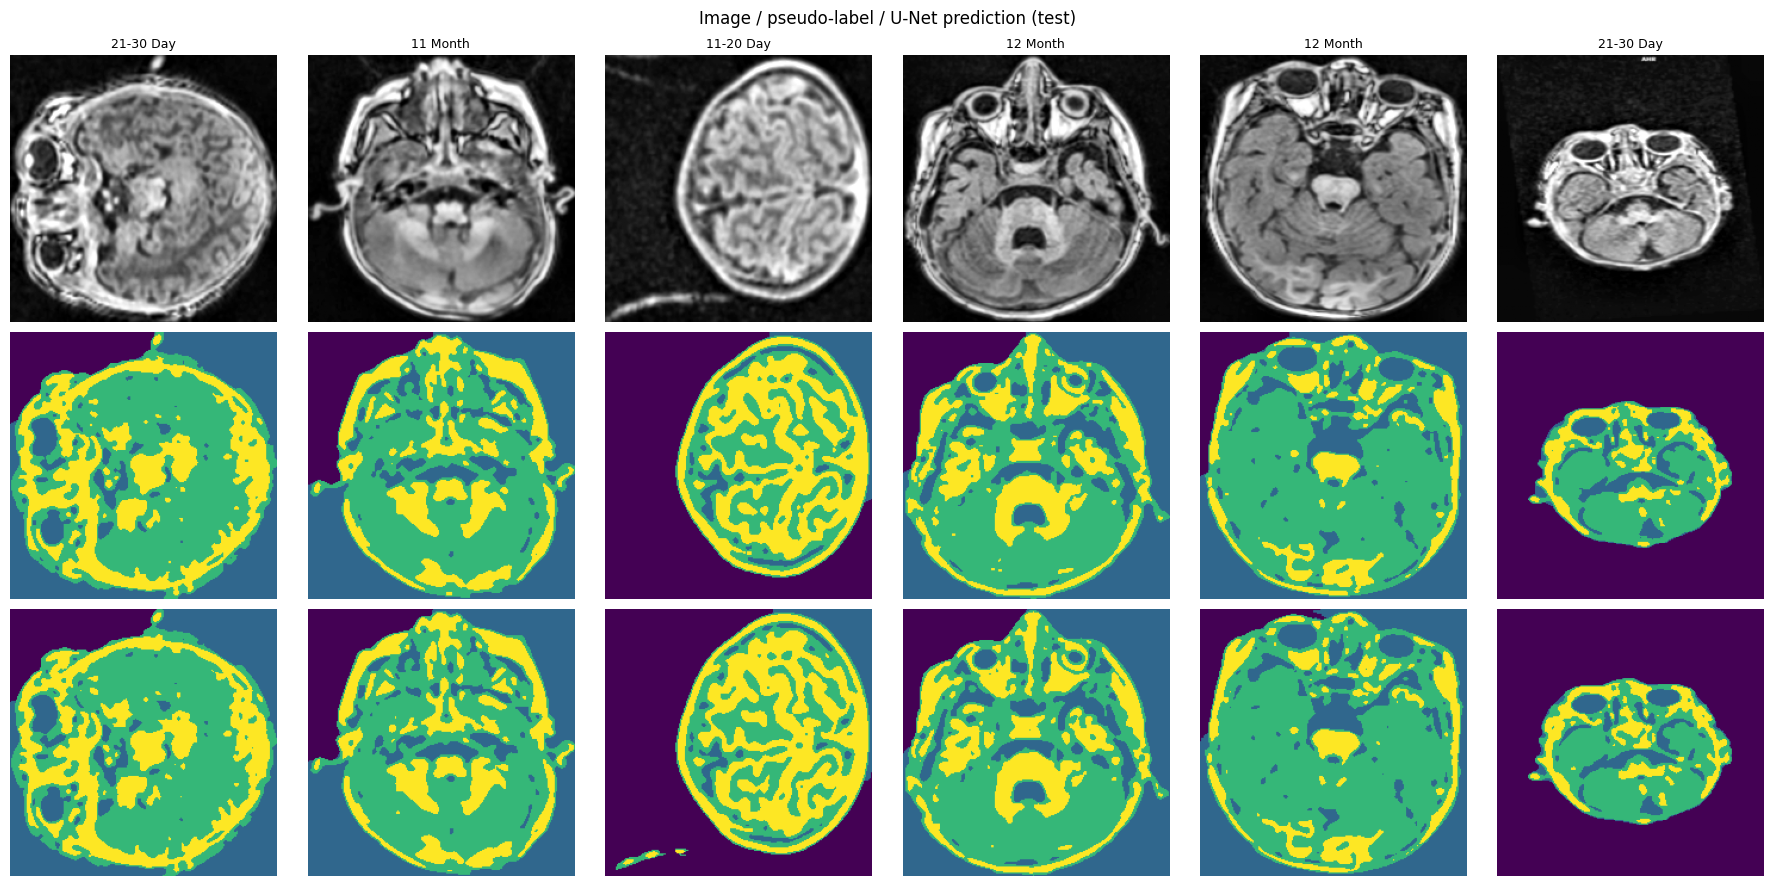

In [12]:
res = eval_seg(seg_model, seg_test_loader)
print("TEST (against pseudo-labels)")
print("  brain-mask Dice :", round(res["brain_dice"], 4))
print("  mean fg Dice    :", round(res["mean_dice_fg"], 4), "| mean fg IoU:", round(res["mean_iou_fg"], 4))
for c, d in enumerate(res["dice_per_class"]):
    print(f"  class {c} Dice   : {d:.4f}")

@torch.no_grad()
def predict_labels(model, X, bs=64):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x = torch.from_numpy(X[i:i + bs]).float().div(255).unsqueeze(1).to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            out.append(model(x).argmax(1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)

P = predict_labels(seg_model, X)          # predicted label maps for every image

pick = np.random.choice(test_idx, 6, replace=False)
fig, ax = plt.subplots(3, 6, figsize=(18, 9))
for k, i in enumerate(pick):
    ax[0, k].imshow(X[i], cmap="gray"); ax[0, k].set_title(df.age_class[i], fontsize=9)
    ax[1, k].imshow(Y[i], cmap="viridis", vmin=0, vmax=K)
    ax[2, k].imshow(P[i], cmap="viridis", vmin=0, vmax=K)
    for r in range(3): ax[r, k].axis("off")
ax[0, 0].set_ylabel("image"); plt.suptitle("Image / pseudo-label / U-Net prediction (test)")
plt.tight_layout(); plt.show()

In [13]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
labels_all = df["label"].to_numpy()

class ClsDS(Dataset):
    def __init__(self, idx, mode, train):
        self.idx, self.mode, self.train = idx, mode, train
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img, pm = X[j], P[j]
        if self.train:
            img, pm = augment_pair(img, pm)
        if self.mode == "baseline":
            c = np.stack([img, img, img])
        else:
            c = np.stack([img, img * (pm > 0), (pm.astype(np.float32) / K * 255).astype(np.uint8)])
        x = (torch.from_numpy(c).float().div(255) - MEAN) / STD
        return x, int(labels_all[j])

def cls_loader(idx, mode, train):
    return DataLoader(ClsDS(idx, mode, train), batch_size=CFG["batch_size"], shuffle=train,
                      num_workers=2, pin_memory=AMP)

@torch.no_grad()
def predict_cls(model, loader):
    model.eval(); ps, ys = [], []
    for x, y in loader:
        with torch.autocast(device_type=device.type, enabled=AMP):
            ps.append(model(x.to(device)).argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ps), np.concatenate(ys)

def scores(p, y):
    return {"acc": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"),
            "acc_within_1_class": float(np.mean(np.abs(p - y) <= 1))}

def train_classifier(name, mode, epochs):
    try:
        model = timm.create_model(name, pretrained=CFG["pretrained"], num_classes=n_classes)
    except Exception as e:
        print("Pretrained weights unavailable, using random init:", repr(e)[:120])
        model = timm.create_model(name, pretrained=False, num_classes=n_classes)
    model = model.to(device)
    tr, va, te = cls_loader(train_idx, mode, True), cls_loader(val_idx, mode, False), cls_loader(test_idx, mode, False)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, epochs=epochs, steps_per_epoch=len(tr), pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    best, best_w = -1, None
    for ep in range(epochs):
        model.train(); tl = 0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item()
        s = scores(*predict_cls(model, va))
        if s["macro_f1"] > best:
            best, best_w = s["macro_f1"], copy.deepcopy(model.state_dict())
        print(f"  ep {ep+1:02d} | loss {tl/len(tr):.4f} | val acc {s['acc']:.4f} | val macro-F1 {s['macro_f1']:.4f}")
    model.load_state_dict(best_w)
    p, y = predict_cls(model, te)
    return {**scores(p, y), "preds": p, "targets": y}

cls_epochs = 1 if CFG["debug"] else CFG["cls_epochs"]
results, store = [], {}
for name in CFG["cls_models"]:
    for mode in ["baseline", "seg_guided"]:
        print(f"\n=== {name} | {mode} ===")
        r = train_classifier(name, mode, cls_epochs)
        store[(name, mode)] = r
        results.append({"model": name, "input": mode, "test_acc": r["acc"],
                        "test_macro_f1": r["macro_f1"], "test_acc_within_1": r["acc_within_1_class"]})

res_df = pd.DataFrame(results).round(4)
res_df.to_csv(OUT / "classification_results.csv", index=False)
res_df


=== convnext_tiny | baseline ===
  ep 01 | loss 1.9825 | val acc 0.4267 | val macro-F1 0.3705
  ep 02 | loss 1.6363 | val acc 0.4728 | val macro-F1 0.4287
  ep 03 | loss 1.3757 | val acc 0.7340 | val macro-F1 0.7313
  ep 04 | loss 1.0667 | val acc 0.7817 | val macro-F1 0.7797
  ep 05 | loss 0.8677 | val acc 0.8901 | val macro-F1 0.8909
  ep 06 | loss 0.7572 | val acc 0.9152 | val macro-F1 0.9146
  ep 07 | loss 0.7098 | val acc 0.9545 | val macro-F1 0.9539
  ep 08 | loss 0.6586 | val acc 0.9236 | val macro-F1 0.9238
  ep 09 | loss 0.6255 | val acc 0.9623 | val macro-F1 0.9618
  ep 10 | loss 0.5940 | val acc 0.9728 | val macro-F1 0.9720
  ep 11 | loss 0.5755 | val acc 0.9791 | val macro-F1 0.9783
  ep 12 | loss 0.5704 | val acc 0.9749 | val macro-F1 0.9739
  ep 13 | loss 0.5675 | val acc 0.9770 | val macro-F1 0.9762
  ep 14 | loss 0.5661 | val acc 0.9749 | val macro-F1 0.9740
  ep 15 | loss 0.5654 | val acc 0.9743 | val macro-F1 0.9735

=== convnext_tiny | seg_guided ===


  ep 01 | loss 1.9495 | val acc 0.4895 | val macro-F1 0.4685
  ep 02 | loss 1.5963 | val acc 0.5000 | val macro-F1 0.4815
  ep 03 | loss 1.3517 | val acc 0.7115 | val macro-F1 0.7082
  ep 04 | loss 1.0525 | val acc 0.8429 | val macro-F1 0.8434
  ep 05 | loss 0.8729 | val acc 0.8791 | val macro-F1 0.8761
  ep 06 | loss 0.7795 | val acc 0.8942 | val macro-F1 0.8943
  ep 07 | loss 0.7046 | val acc 0.9293 | val macro-F1 0.9276
  ep 08 | loss 0.6617 | val acc 0.9524 | val macro-F1 0.9513
  ep 09 | loss 0.6269 | val acc 0.9686 | val macro-F1 0.9679
  ep 10 | loss 0.5938 | val acc 0.9749 | val macro-F1 0.9739
  ep 11 | loss 0.5777 | val acc 0.9754 | val macro-F1 0.9749
  ep 12 | loss 0.5721 | val acc 0.9764 | val macro-F1 0.9758
  ep 13 | loss 0.5683 | val acc 0.9743 | val macro-F1 0.9736
  ep 14 | loss 0.5665 | val acc 0.9733 | val macro-F1 0.9724
  ep 15 | loss 0.5660 | val acc 0.9754 | val macro-F1 0.9745

=== swin_tiny_patch4_window7_224 | baseline ===


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

  ep 01 | loss 2.0647 | val acc 0.4764 | val macro-F1 0.4542
  ep 02 | loss 1.6362 | val acc 0.4832 | val macro-F1 0.4652
  ep 03 | loss 1.3738 | val acc 0.6906 | val macro-F1 0.6824
  ep 04 | loss 1.1318 | val acc 0.8545 | val macro-F1 0.8546
  ep 05 | loss 0.9730 | val acc 0.8105 | val macro-F1 0.8064
  ep 06 | loss 0.8539 | val acc 0.9241 | val macro-F1 0.9226
  ep 07 | loss 0.7682 | val acc 0.9497 | val macro-F1 0.9485
  ep 08 | loss 0.7135 | val acc 0.9482 | val macro-F1 0.9484
  ep 09 | loss 0.6628 | val acc 0.9665 | val macro-F1 0.9661
  ep 10 | loss 0.6277 | val acc 0.9780 | val macro-F1 0.9775
  ep 11 | loss 0.6064 | val acc 0.9806 | val macro-F1 0.9799
  ep 12 | loss 0.5892 | val acc 0.9806 | val macro-F1 0.9799
  ep 15 | loss 0.5762 | val acc 0.9770 | val macro-F1 0.9761

=== swin_tiny_patch4_window7_224 | seg_guided ===
  ep 01 | loss 2.0592 | val acc 0.3827 | val macro-F1 0.3320
  ep 02 | loss 1.6113 | val acc 0.6366 | val macro-F1 0.6248
  ep 03 | loss 1.3541 | val acc 0.

,model,input,test_acc,test_macro_f1,test_acc_within_1
0,convnext_tiny,baseline,0.9745,0.9737,0.9978
1,convnext_tiny,seg_guided,0.9739,0.9731,0.9984
2,swin_tiny_patch4_window7_224,baseline,0.9799,0.9792,0.9991
3,swin_tiny_patch4_window7_224,seg_guided,0.9767,0.9758,0.9987


Best configuration: ('swin_tiny_patch4_window7_224', 'baseline')
              precision    recall  f1-score   support

    0-10 Day       1.00      0.99      0.99       244
   11-20 Day       0.99      1.00      0.99       250
   21-30 Day       1.00      1.00      1.00       240
     2 Month       0.95      0.98      0.97       211
     3 Month       0.98      0.95      0.96       204
     4 Month       1.00      1.00      1.00       229
     5 Month       1.00      1.00      1.00       217
     6 Month       1.00      1.00      1.00       255
     7 Month       1.00      1.00      1.00       220
     8 Month       0.97      0.92      0.95       235
     9 Month       0.92      0.96      0.94       201
    10 Month       0.99      1.00      0.99       211
    11 Month       0.92      1.00      0.96       231
    12 Month       1.00      0.92      0.96       232

    accuracy                           0.98      3180
   macro avg       0.98      0.98      0.98      3180
weighted avg   

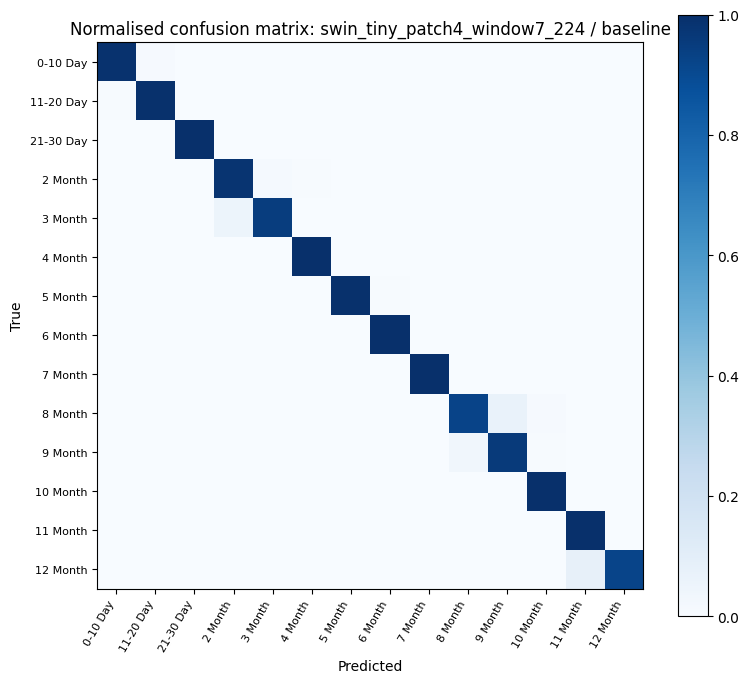

In [14]:
best_key = max(store, key=lambda k: store[k]["macro_f1"])
r = store[best_key]
print("Best configuration:", best_key)
print(classification_report(r["targets"], r["preds"], target_names=class_order, zero_division=0))

cm = confusion_matrix(r["targets"], r["preds"], labels=list(range(n_classes)))
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_classes)); ax.set_xticklabels(class_order, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(n_classes)); ax.set_yticklabels(class_order, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Normalised confusion matrix: {best_key[0]} / {best_key[1]}")
plt.colorbar(im); plt.tight_layout(); plt.savefig(OUT / "confusion_matrix.png", dpi=200); plt.show()

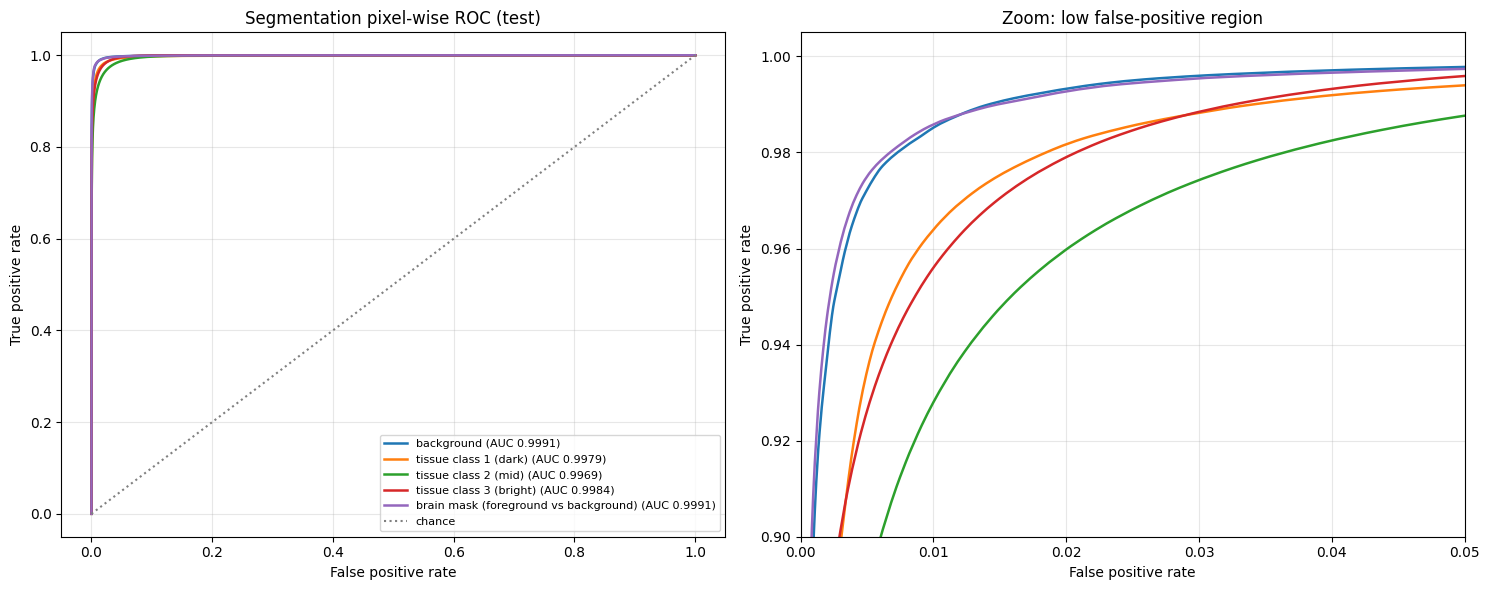

                               target  pixel_auc
                           background     0.9991
                tissue class 1 (dark)     0.9979
                 tissue class 2 (mid)     0.9969
              tissue class 3 (bright)     0.9984
brain mask (foreground vs background)     0.9991


In [15]:
# ROC / AUC cells for your notebook. Each "# %%" block is one cell.
# Needs the objects already in your notebook: torch, np, plt, pd, device, AMP, OUT,
# n_classes, class_order, K, N_SEG_CLASSES, seg_model, seg_test_loader, store.

# %% CELL A: classification -- probabilities
# 1) In cell 13, change the last two lines of train_classifier from
#        p, y = predict_cls(model, te)
#        return {**scores(p, y), "preds": p, "targets": y}
#    to
#        p, y = predict_cls(model, te)
#        probs = predict_proba(model, te)
#        torch.save(model.state_dict(), OUT / f"{name}_{mode}.pt")
#        return {**scores(p, y), "preds": p, "targets": y, "probs": probs}
# 2) Put predict_proba below ABOVE train_classifier (it is only needed there), then re-run.
#    To save time, retrain just your best config instead of all four:
#        r = train_classifier("swin_tiny_patch4_window7_224", "baseline", cls_epochs)
#        store[("swin_tiny_patch4_window7_224", "baseline")] = r

@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); out = []
    for x, _ in loader:                      # test loader is not shuffled, so order matches targets
        with torch.autocast(device_type=device.type, enabled=AMP):
            lg = model(x.to(device))
        out.append(lg.float().softmax(1).cpu().numpy())
    return np.concatenate(out)

# %% CELL B: classification -- one-vs-rest ROC, per-class + macro + micro AUC
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

def classification_roc(r, title, fname):
    y, pr = r["targets"], r["probs"]
    Yb = label_binarize(y, classes=list(range(n_classes)))
    fpr, tpr, aucs = {}, {}, {}
    for c in range(n_classes):
        fpr[c], tpr[c], _ = roc_curve(Yb[:, c], pr[:, c])
        aucs[c] = auc(fpr[c], tpr[c])
    grid = np.linspace(0, 1, 1001)
    macro_tpr = np.mean([np.interp(grid, fpr[c], tpr[c]) for c in range(n_classes)], axis=0)
    macro_auc = roc_auc_score(y, pr, multi_class="ovr", average="macro")
    fpr_mi, tpr_mi, _ = roc_curve(Yb.ravel(), pr.ravel())
    micro_auc = auc(fpr_mi, tpr_mi)

    fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
    cmap = plt.cm.tab20
    for a, zoom in zip(ax, (False, True)):
        for c in range(n_classes):
            a.plot(fpr[c], tpr[c], lw=1, color=cmap(c), label=f"{class_order[c]} (AUC {aucs[c]:.4f})")
        a.plot(grid, macro_tpr, "k-", lw=2.5, label=f"macro-average (AUC {macro_auc:.4f})")
        a.plot(fpr_mi, tpr_mi, "k--", lw=2, label=f"micro-average (AUC {micro_auc:.4f})")
        if not zoom:
            a.plot([0, 1], [0, 1], ":", color="gray", label="chance")
            a.set_title(title)
        else:
            a.set_xlim(0, 0.05); a.set_ylim(0.9, 1.005); a.set_title("Zoom: low false-positive region")
        a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate"); a.grid(alpha=.3)
    ax[1].legend(fontsize=8, loc="lower right", ncol=1, bbox_to_anchor=(1.55, 0.0))
    plt.tight_layout(); plt.savefig(OUT / fname, dpi=200, bbox_inches="tight"); plt.show()

    tab = pd.DataFrame({"class": class_order, "auc_ovr": [aucs[c] for c in range(n_classes)]})
    tab.loc[len(tab)] = ["macro", macro_auc]; tab.loc[len(tab)] = ["micro", micro_auc]
    return tab.round(4)

for key, r in store.items():
    if "probs" not in r:
        continue
    print(f"\n=== {key[0]} | {key[1]} ===")
    tab = classification_roc(r, f"One-vs-rest ROC: {key[0]} / {key[1]}", f"roc_cls_{key[0]}_{key[1]}.png")
    tab.to_csv(OUT / f"auc_cls_{key[0]}_{key[1]}.csv", index=False)
    print(tab.to_string(index=False))

# %% CELL C: segmentation -- pixel-wise ROC (histogram-based, memory-safe)
# Scores are log-odds of each class vs the rest, binned into NBINS bins. Log-odds is a monotone
# function of the class probability, so the ROC is identical, but extreme values stay resolved.
NBINS, SMAX, IGNORE = 4000, 15.0, 255

def _bin(s):
    return ((s.clamp(-SMAX, SMAX) + SMAX) / (2 * SMAX) * (NBINS - 1)).long()

@torch.no_grad()
def seg_roc_stats(model, loader):
    model.eval()
    n = N_SEG_CLASSES
    pos = torch.zeros(n + 1, NBINS, dtype=torch.long, device=device)    # last row = brain vs background
    neg = torch.zeros(n + 1, NBINS, dtype=torch.long, device=device)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            lg = model(x)
        lg = lg.float()
        valid = y != IGNORE
        scores = []
        for c in range(n):
            others = torch.cat([lg[:, :c], lg[:, c + 1:]], 1).logsumexp(1)
            scores.append((lg[:, c] - others, y == c))
        scores.append((lg[:, 1:].logsumexp(1) - lg[:, 0], y > 0))          # brain mask vs background
        for c, (s, t) in enumerate(scores):
            b = _bin(s)
            pos[c] += torch.bincount(b[t & valid], minlength=NBINS)
            neg[c] += torch.bincount(b[(~t) & valid], minlength=NBINS)
    return pos.cpu().numpy().astype(np.float64), neg.cpu().numpy().astype(np.float64)

def roc_from_hist(pos, neg):
    tpr = np.concatenate([[0], np.cumsum(pos[::-1]) / max(pos.sum(), 1)])
    fpr = np.concatenate([[0], np.cumsum(neg[::-1]) / max(neg.sum(), 1)])
    trap = getattr(np, "trapezoid", None) or np.trapz
    return fpr, tpr, float(trap(tpr, fpr))

def segmentation_roc(model, loader, fname="roc_segmentation.png"):
    pos, neg = seg_roc_stats(model, loader)
    names = ["background"] + [f"tissue class {c} ({['dark','mid','bright','brightest'][c-1]})" for c in range(1, N_SEG_CLASSES)] \
            + ["brain mask (foreground vs background)"]
    rows, curves = [], []
    for c, nm in enumerate(names):
        f, t, a = roc_from_hist(pos[c], neg[c])
        curves.append((nm, f, t, a)); rows.append({"target": nm, "pixel_auc": a})
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    for a_, zoom in zip(ax, (False, True)):
        for nm, f, t, a in curves:
            a_.plot(f, t, lw=1.8, label=f"{nm} (AUC {a:.4f})")
        if not zoom:
            a_.plot([0, 1], [0, 1], ":", color="gray", label="chance"); a_.set_title("Segmentation pixel-wise ROC (test)")
        else:
            a_.set_xlim(0, 0.05); a_.set_ylim(0.9, 1.005); a_.set_title("Zoom: low false-positive region")
        a_.set_xlabel("False positive rate"); a_.set_ylabel("True positive rate"); a_.grid(alpha=.3)
    ax[0].legend(fontsize=8, loc="lower right")
    plt.tight_layout(); plt.savefig(OUT / fname, dpi=200, bbox_inches="tight"); plt.show()
    return pd.DataFrame(rows).round(4)

# use seg_test_loader (original notebook) or te_loader (if you ran seg_improvements.py)
seg_auc = segmentation_roc(seg_model, seg_test_loader)
seg_auc.to_csv(OUT / "auc_segmentation.csv", index=False)
print(seg_auc.to_string(index=False))

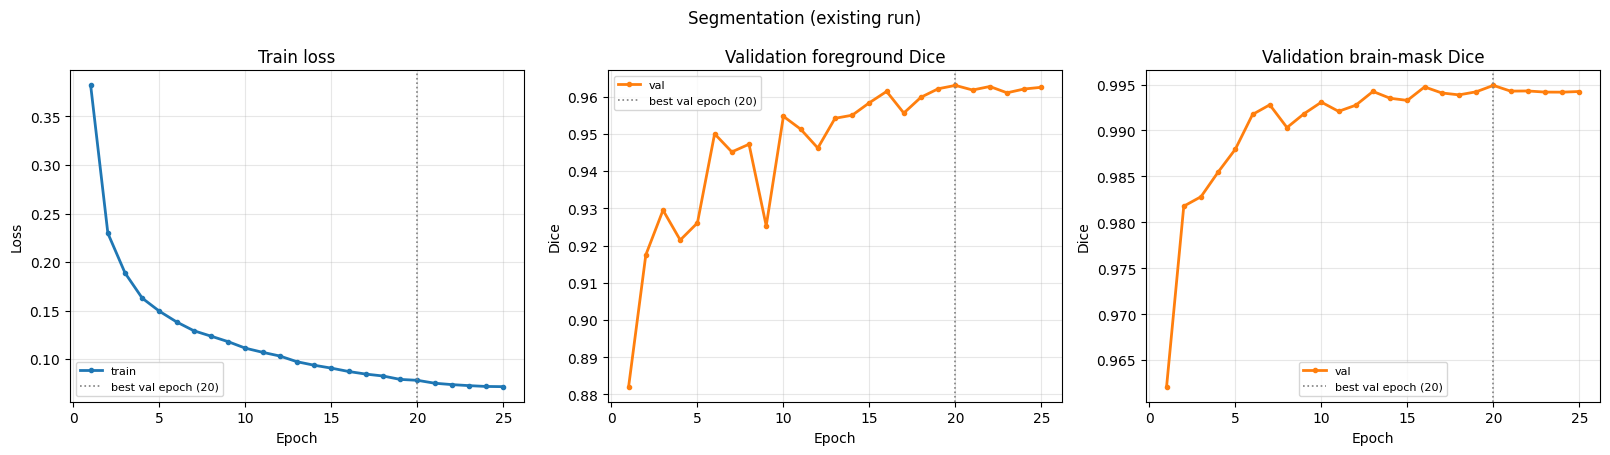

ep 01 | train loss 0.3793 Dice 0.8423 | val Dice 0.8748 | test Dice 0.8739
ep 02 | train loss 0.2187 Dice 0.8944 | val Dice 0.9009 | test Dice 0.9008
ep 03 | train loss 0.1762 Dice 0.9098 | val Dice 0.9237 | test Dice 0.9235
ep 04 | train loss 0.1563 Dice 0.9176 | val Dice 0.8903 | test Dice 0.8885
ep 05 | train loss 0.1407 Dice 0.9242 | val Dice 0.9156 | test Dice 0.9142
ep 06 | train loss 0.1355 Dice 0.9272 | val Dice 0.9489 | test Dice 0.9494
ep 07 | train loss 0.1241 Dice 0.9312 | val Dice 0.9478 | test Dice 0.9483
ep 08 | train loss 0.1168 Dice 0.9347 | val Dice 0.9423 | test Dice 0.9431
ep 09 | train loss 0.1113 Dice 0.9371 | val Dice 0.9511 | test Dice 0.9508
ep 10 | train loss 0.1054 Dice 0.9398 | val Dice 0.9516 | test Dice 0.9516
ep 11 | train loss 0.1031 Dice 0.9407 | val Dice 0.9537 | test Dice 0.9543
ep 12 | train loss 0.0978 Dice 0.9435 | val Dice 0.9527 | test Dice 0.9529
ep 13 | train loss 0.0948 Dice 0.9449 | val Dice 0.9589 | test Dice 0.9592
ep 14 | train loss 0.0905

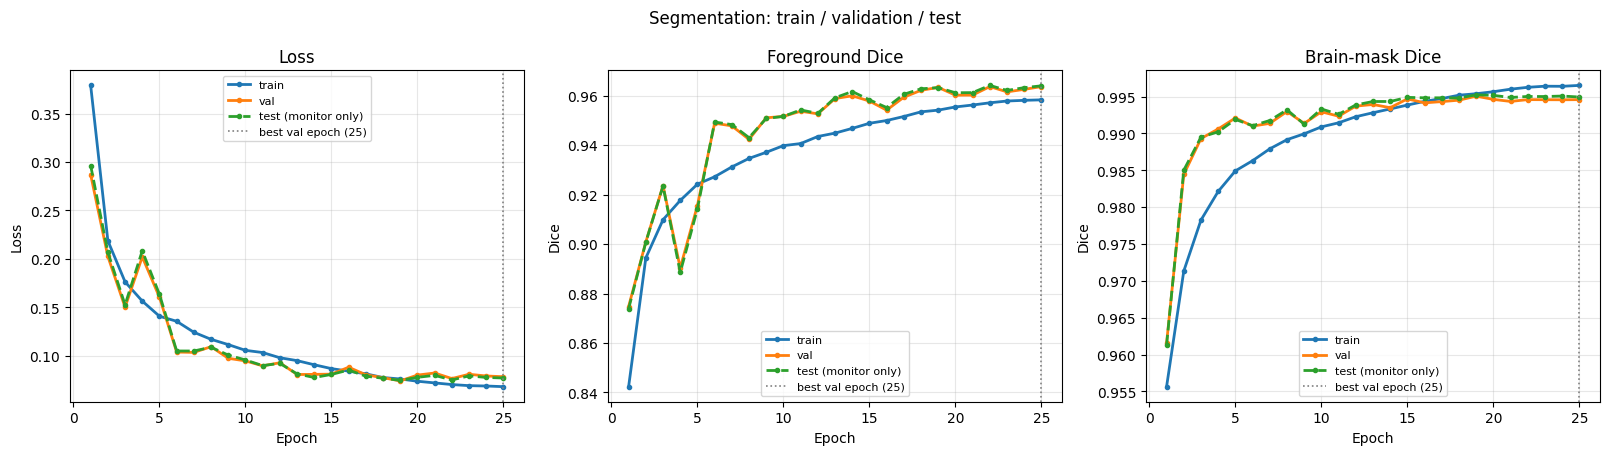


=== convnext_tiny | baseline ===
  ep 01 | train loss 1.7235 acc 0.3726 | val acc 0.4895 F1 0.4701 | test acc 0.4789
  ep 02 | train loss 1.3062 acc 0.5193 | val acc 0.6267 F1 0.6240 | test acc 0.6135
  ep 03 | train loss 1.0235 acc 0.6400 | val acc 0.6770 F1 0.6559 | test acc 0.6679
  ep 04 | train loss 0.6445 acc 0.7992 | val acc 0.8058 F1 0.8040 | test acc 0.8170
  ep 05 | train loss 0.4589 acc 0.8630 | val acc 0.8995 F1 0.8991 | test acc 0.9041
  ep 06 | train loss 0.3360 acc 0.9126 | val acc 0.9141 F1 0.9146 | test acc 0.9208
  ep 09 | train loss 0.1824 acc 0.9659 | val acc 0.9686 F1 0.9679 | test acc 0.9711
  ep 10 | train loss 0.1486 acc 0.9750 | val acc 0.9733 F1 0.9728 | test acc 0.9739
  ep 11 | train loss 0.1316 acc 0.9813 | val acc 0.9791 F1 0.9785 | test acc 0.9783
  ep 12 | train loss 0.1232 acc 0.9834 | val acc 0.9806 F1 0.9799 | test acc 0.9774
  ep 13 | train loss 0.1210 acc 0.9849 | val acc 0.9770 F1 0.9762 | test acc 0.9752
  ep 14 | train loss 0.1194 acc 0.9861 | v

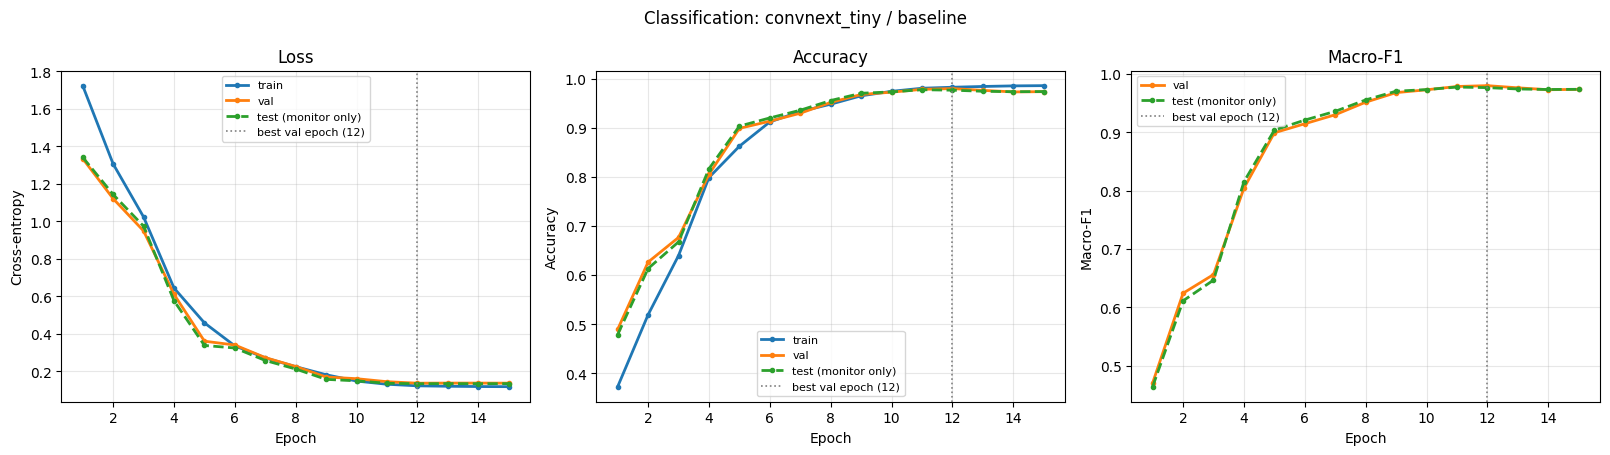


=== convnext_tiny | seg_guided ===
  ep 01 | train loss 1.8334 acc 0.3369 | val acc 0.4555 F1 0.4312 | test acc 0.4274
  ep 02 | train loss 1.4273 acc 0.4688 | val acc 0.4377 F1 0.4064 | test acc 0.4425
  ep 03 | train loss 1.0837 acc 0.6111 | val acc 0.6796 F1 0.6677 | test acc 0.6808
  ep 04 | train loss 0.7251 acc 0.7581 | val acc 0.7529 F1 0.7502 | test acc 0.7544
  ep 05 | train loss 0.4942 acc 0.8543 | val acc 0.9120 F1 0.9119 | test acc 0.9113
  ep 06 | train loss 0.3650 acc 0.9022 | val acc 0.8901 F1 0.8906 | test acc 0.8821
  ep 07 | train loss 0.2851 acc 0.9291 | val acc 0.9361 F1 0.9350 | test acc 0.9456
  ep 08 | train loss 0.2220 acc 0.9492 | val acc 0.9487 F1 0.9484 | test acc 0.9616
  ep 09 | train loss 0.1873 acc 0.9613 | val acc 0.9707 F1 0.9699 | test acc 0.9682
  ep 10 | train loss 0.1509 acc 0.9746 | val acc 0.9728 F1 0.9724 | test acc 0.9761
  ep 11 | train loss 0.1356 acc 0.9786 | val acc 0.9728 F1 0.9719 | test acc 0.9786
  ep 12 | train loss 0.1247 acc 0.9835 |

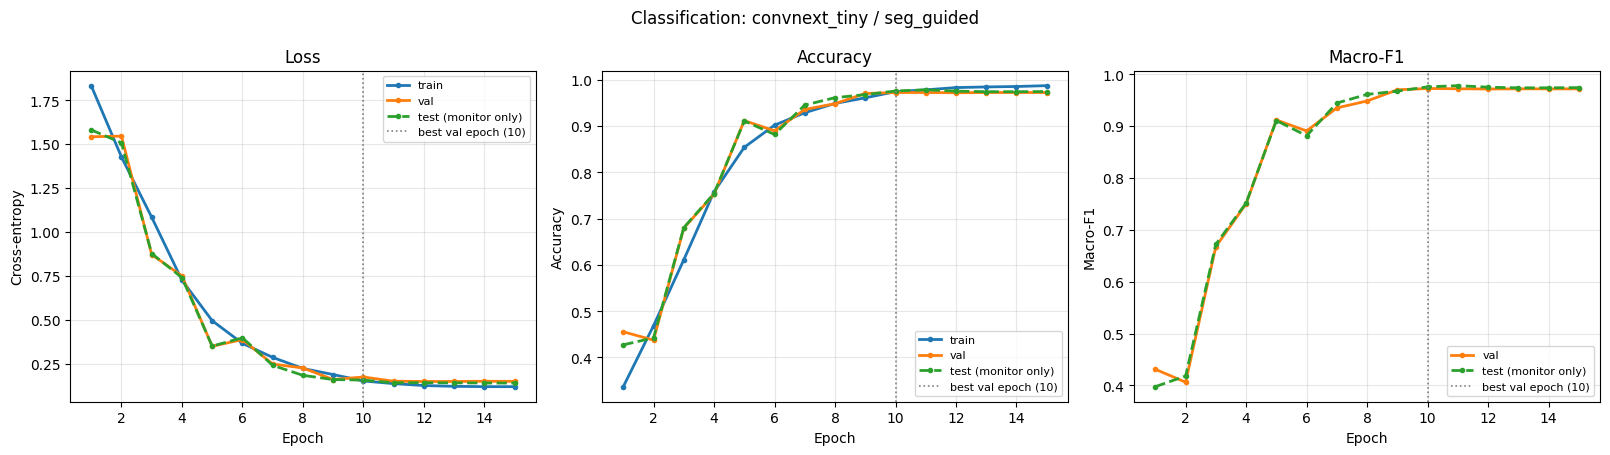


=== swin_tiny_patch4_window7_224 | baseline ===
  ep 01 | train loss 1.8758 acc 0.3285 | val acc 0.5293 F1 0.5113 | test acc 0.5170
  ep 02 | train loss 1.3091 acc 0.5324 | val acc 0.6084 F1 0.5876 | test acc 0.5972
  ep 03 | train loss 1.0015 acc 0.6517 | val acc 0.7403 F1 0.7378 | test acc 0.7283
  ep 04 | train loss 0.7321 acc 0.7582 | val acc 0.7958 F1 0.7938 | test acc 0.7956
  ep 05 | train loss 0.5403 acc 0.8316 | val acc 0.8895 F1 0.8890 | test acc 0.8764
  ep 06 | train loss 0.4206 acc 0.8837 | val acc 0.9037 F1 0.9024 | test acc 0.9157
  ep 07 | train loss 0.3372 acc 0.9099 | val acc 0.9487 F1 0.9483 | test acc 0.9525
  ep 08 | train loss 0.2659 acc 0.9383 | val acc 0.9592 F1 0.9584 | test acc 0.9604
  ep 09 | train loss 0.2195 acc 0.9541 | val acc 0.9723 F1 0.9714 | test acc 0.9704
  ep 10 | train loss 0.1805 acc 0.9656 | val acc 0.9733 F1 0.9726 | test acc 0.9723
  ep 11 | train loss 0.1542 acc 0.9759 | val acc 0.9796 F1 0.9788 | test acc 0.9789
  ep 12 | train loss 0.1372

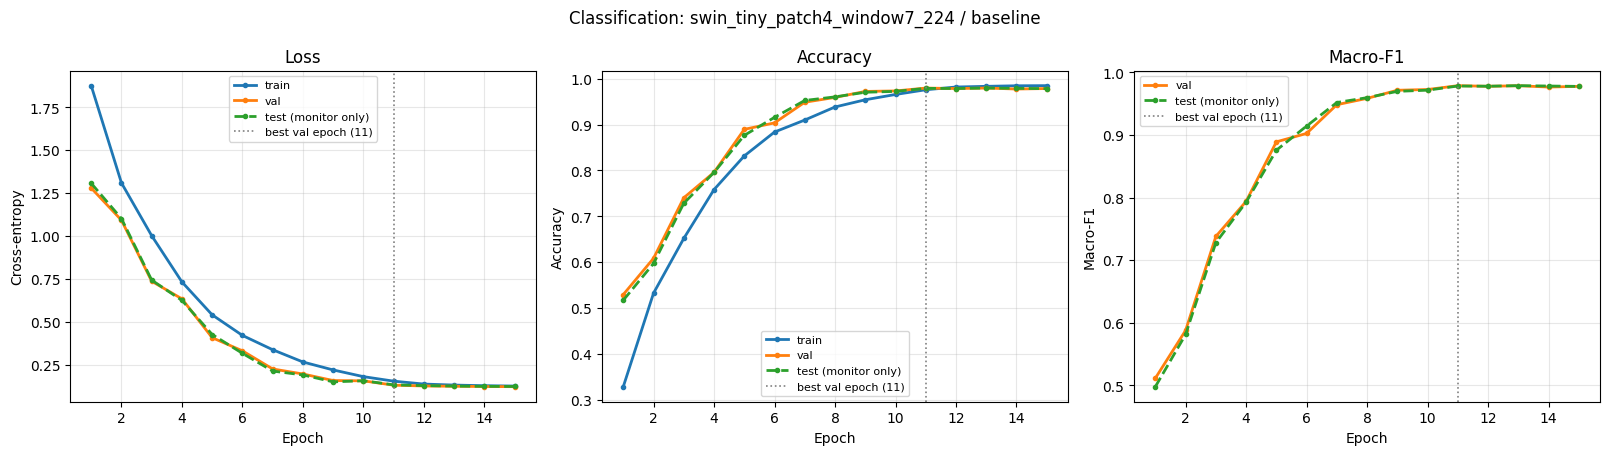


=== swin_tiny_patch4_window7_224 | seg_guided ===
  ep 01 | train loss 1.9238 acc 0.3120 | val acc 0.4466 F1 0.4204 | test acc 0.4267
  ep 02 | train loss 1.3534 acc 0.5095 | val acc 0.5696 F1 0.5565 | test acc 0.5686
  ep 03 | train loss 1.0587 acc 0.6293 | val acc 0.7031 F1 0.7014 | test acc 0.7053
  ep 04 | train loss 0.7686 acc 0.7404 | val acc 0.8738 F1 0.8729 | test acc 0.8708
  ep 05 | train loss 0.5675 acc 0.8264 | val acc 0.9126 F1 0.9120 | test acc 0.9198
  ep 06 | train loss 0.4437 acc 0.8666 | val acc 0.9340 F1 0.9336 | test acc 0.9308
  ep 07 | train loss 0.3402 acc 0.9087 | val acc 0.9440 F1 0.9434 | test acc 0.9437
  ep 08 | train loss 0.2779 acc 0.9297 | val acc 0.9534 F1 0.9531 | test acc 0.9535
  ep 09 | train loss 0.2170 acc 0.9538 | val acc 0.9733 F1 0.9726 | test acc 0.9695
  ep 10 | train loss 0.1842 acc 0.9645 | val acc 0.9702 F1 0.9692 | test acc 0.9730
  ep 11 | train loss 0.1547 acc 0.9737 | val acc 0.9775 F1 0.9769 | test acc 0.9755
  ep 12 | train loss 0.13

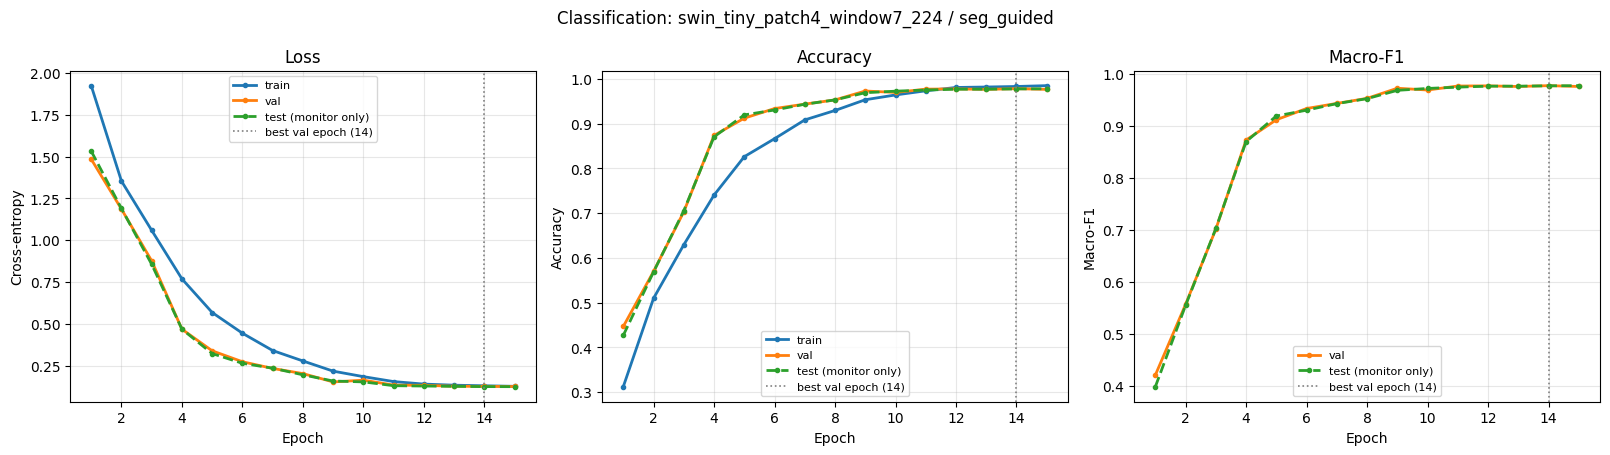

Best config (by validation macro-F1): ('convnext_tiny', 'baseline') | val F1 0.9799 | test acc 0.9774 | test macro-F1 0.9765


In [20]:
# Training / validation / test curves. Each "# %%" block is one cell.
# Needs from your notebook: torch, nn, F, np, pd, plt, timm, copy, device, AMP, OUT, CFG,
# n_classes, N_SEG_CLASSES, train_idx/val_idx/test_idx, cls_loader, scores, TimmUNet,
# seg_loss, seg_train_loader, seg_val_loader, seg_test_loader, seg_hist.

# %% CELL 1: generic plotting helper (run first)
import numpy as np
import matplotlib.pyplot as plt

STYLE = {"train": ("tab:blue", "-"), "val": ("tab:orange", "-"), "test": ("tab:green", "--")}

def plot_curves(H, panels, title, fname=None, best_epoch=None):
    """H: dict of lists. panels: list of (panel_title, ylabel, {split: key})."""
    fig, axes = plt.subplots(1, len(panels), figsize=(5.4 * len(panels), 4.6))
    axes = np.atleast_1d(axes)
    for ax, (ptitle, ylabel, keys) in zip(axes, panels):
        for split, key in keys.items():
            y = np.asarray(H[key], dtype=float)
            if np.all(np.isnan(y)):
                continue
            col, ls = STYLE[split]
            lab = split + (" (monitor only)" if split == "test" else "")
            ax.plot(np.arange(1, len(y) + 1), y, color=col, ls=ls, lw=2, marker="o", ms=3, label=lab)
        if best_epoch:
            ax.axvline(best_epoch, color="gray", ls=":", lw=1.2, label=f"best val epoch ({best_epoch})")
        ax.set_title(ptitle); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout()
    if fname:
        plt.savefig(OUT / fname, dpi=200, bbox_inches="tight")
    plt.show()

# %% CELL 2: quick plot of the segmentation run you ALREADY have (no retraining)
# seg_hist rows are (train_loss, val_fg_dice, val_brain_dice)
tl, vd, vb = zip(*seg_hist)
H0 = {"train_loss": tl, "val_dice": vd, "val_brain": vb}
best_ep0 = int(np.argmax(vd)) + 1
plot_curves(H0,
            [("Train loss", "Loss", {"train": "train_loss"}),
             ("Validation foreground Dice", "Dice", {"val": "val_dice"}),
             ("Validation brain-mask Dice", "Dice", {"val": "val_brain"})],
            "Segmentation (existing run)", "curves_segmentation_basic.png", best_ep0)

# %% CELL 3: segmentation with full train / val / test curves (retrains, ~same time as before)
@torch.no_grad()
def _seg_eval(model, loader):
    model.eval(); n = N_SEG_CLASSES
    tp = torch.zeros(n, device=device); fp = torch.zeros(n, device=device); fn = torch.zeros(n, device=device)
    btp = torch.zeros((), device=device); bfp = torch.zeros((), device=device); bfn = torch.zeros((), device=device)
    tl, nb = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            lg = model(x)
        tl += seg_loss(lg.float(), y).item(); nb += 1
        pred = lg.argmax(1)
        for c in range(n):
            tp[c] += ((pred == c) & (y == c)).sum(); fp[c] += ((pred == c) & (y != c)).sum(); fn[c] += ((pred != c) & (y == c)).sum()
        pb, yb = pred > 0, y > 0
        btp += (pb & yb).sum(); bfp += (pb & ~yb).sum(); bfn += (~pb & yb).sum()
    eps = 1e-7
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    return tl / nb, dice[1:].mean().item(), ((2 * btp + eps) / (2 * btp + bfp + bfn + eps)).item()

def train_segmentation_h(epochs, track_test=True):
    model = TimmUNet(CFG["seg_encoder"], N_SEG_CLASSES, CFG["pretrained"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    keys = ["train_loss", "train_dice", "train_brain", "val_loss", "val_dice", "val_brain",
            "test_loss", "test_dice", "test_brain"]
    H = {k: [] for k in keys}
    best, best_w, best_ep, n = -1, None, 0, N_SEG_CLASSES
    for ep in range(epochs):
        model.train(); tl = 0.0
        tp = torch.zeros(n, device=device); fp = torch.zeros(n, device=device); fn = torch.zeros(n, device=device)
        btp = torch.zeros((), device=device); bfp = torch.zeros((), device=device); bfn = torch.zeros((), device=device)
        for x, y in seg_train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=AMP):
                lg = model(x); loss = seg_loss(lg, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()
            with torch.no_grad():                       # running train Dice on augmented batches
                pred = lg.detach().argmax(1)
                for c in range(n):
                    tp[c] += ((pred == c) & (y == c)).sum(); fp[c] += ((pred == c) & (y != c)).sum(); fn[c] += ((pred != c) & (y == c)).sum()
                pb, yb = pred > 0, y > 0
                btp += (pb & yb).sum(); bfp += (pb & ~yb).sum(); bfn += (~pb & yb).sum()
        sched.step()
        eps = 1e-7
        H["train_loss"].append(tl / len(seg_train_loader))
        H["train_dice"].append((((2 * tp + eps) / (2 * tp + fp + fn + eps))[1:].mean()).item())
        H["train_brain"].append(((2 * btp + eps) / (2 * btp + bfp + bfn + eps)).item())
        vl, vd, vb = _seg_eval(model, seg_val_loader)
        H["val_loss"].append(vl); H["val_dice"].append(vd); H["val_brain"].append(vb)
        if track_test:
            tsl, tsd, tsb = _seg_eval(model, seg_test_loader)
        else:
            tsl = tsd = tsb = float("nan")
        H["test_loss"].append(tsl); H["test_dice"].append(tsd); H["test_brain"].append(tsb)
        if vd > best:                                    # selection uses VALIDATION only
            best, best_w, best_ep = vd, copy.deepcopy(model.state_dict()), ep + 1
        print(f"ep {ep+1:02d} | train loss {H['train_loss'][-1]:.4f} Dice {H['train_dice'][-1]:.4f} | "
              f"val Dice {vd:.4f} | test Dice {tsd:.4f}")
    model.load_state_dict(best_w)
    return model, H, best_ep

seg_model_h, seg_H, seg_best_ep = train_segmentation_h(CFG["seg_epochs"])
plot_curves(seg_H,
            [("Loss", "Loss", {"train": "train_loss", "val": "val_loss", "test": "test_loss"}),
             ("Foreground Dice", "Dice", {"train": "train_dice", "val": "val_dice", "test": "test_dice"}),
             ("Brain-mask Dice", "Dice", {"train": "train_brain", "val": "val_brain", "test": "test_brain"})],
            "Segmentation: train / validation / test", "curves_segmentation.png", seg_best_ep)
pd.DataFrame(seg_H).round(4).to_csv(OUT / "history_segmentation.csv", index_label="epoch0")

# %% CELL 4: classification with full train / val / test curves + probabilities (for ROC)
def _cls_eval(model, loader):
    model.eval(); lgs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            with torch.autocast(device_type=device.type, enabled=AMP):
                lg = model(x.to(device))
            lgs.append(lg.float().cpu()); ys.append(y)
    lg, y = torch.cat(lgs), torch.cat(ys)
    loss = F.cross_entropy(lg, y).item()
    prob = lg.softmax(1).numpy(); pred = prob.argmax(1); y = y.numpy()
    return {"loss": loss, **scores(pred, y)}, pred, y, prob

def train_classifier_h(name, mode, epochs, track_test=True):
    try:
        model = timm.create_model(name, pretrained=CFG["pretrained"], num_classes=n_classes)
    except Exception as e:
        print("Pretrained weights unavailable, using random init:", repr(e)[:120])
        model = timm.create_model(name, pretrained=False, num_classes=n_classes)
    model = model.to(device)
    tr, va, te = cls_loader(train_idx, mode, True), cls_loader(val_idx, mode, False), cls_loader(test_idx, mode, False)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, epochs=epochs, steps_per_epoch=len(tr), pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    keys = ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "test_loss", "test_acc", "test_f1"]
    H = {k: [] for k in keys}
    best, best_w, best_ep = -1, None, 0
    for ep in range(epochs):
        model.train(); tl = tc = tn = 0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=AMP):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            with torch.no_grad():                        # plain CE so train/val/test losses are comparable
                o = out.detach().float()
                tl += F.cross_entropy(o, y, reduction="sum").item(); tc += (o.argmax(1) == y).sum().item(); tn += len(y)
        v = _cls_eval(model, va)[0]
        t = _cls_eval(model, te)[0] if track_test else {"loss": np.nan, "acc": np.nan, "macro_f1": np.nan}
        H["train_loss"].append(tl / tn); H["train_acc"].append(tc / tn)
        H["val_loss"].append(v["loss"]); H["val_acc"].append(v["acc"]); H["val_f1"].append(v["macro_f1"])
        H["test_loss"].append(t["loss"]); H["test_acc"].append(t["acc"]); H["test_f1"].append(t["macro_f1"])
        if v["macro_f1"] > best:                         # selection uses VALIDATION only
            best, best_w, best_ep = v["macro_f1"], copy.deepcopy(model.state_dict()), ep + 1
        print(f"  ep {ep+1:02d} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val acc {v['acc']:.4f} F1 {v['macro_f1']:.4f}"
              + (f" | test acc {t['acc']:.4f}" if track_test else ""))
    model.load_state_dict(best_w)
    torch.save(model.state_dict(), OUT / f"{name}_{mode}.pt")
    tfin, p, y, prob = _cls_eval(model, te)
    return {**scores(p, y), "preds": p, "targets": y, "probs": prob,
            "history": H, "best_epoch": best_ep, "val_macro_f1": best}

cls_store = {}
for name in CFG["cls_models"]:
    for mode in ["baseline", "seg_guided"]:
        print(f"\n=== {name} | {mode} ===")
        r = train_classifier_h(name, mode, CFG["cls_epochs"])
        cls_store[(name, mode)] = r
        plot_curves(r["history"],
                    [("Loss", "Cross-entropy", {"train": "train_loss", "val": "val_loss", "test": "test_loss"}),
                     ("Accuracy", "Accuracy", {"train": "train_acc", "val": "val_acc", "test": "test_acc"}),
                     ("Macro-F1", "Macro-F1", {"val": "val_f1", "test": "test_f1"})],
                    f"Classification: {name} / {mode}", f"curves_cls_{name}_{mode}.png", r["best_epoch"])
        pd.DataFrame(r["history"]).round(4).to_csv(OUT / f"history_cls_{name}_{mode}.csv", index_label="epoch0")

# choose the best configuration by VALIDATION macro-F1, then report its test score once
best_key = max(cls_store, key=lambda k: cls_store[k]["val_macro_f1"])
print("Best config (by validation macro-F1):", best_key,
      "| val F1 %.4f | test acc %.4f | test macro-F1 %.4f" %
      (cls_store[best_key]["val_macro_f1"], cls_store[best_key]["acc"], cls_store[best_key]["macro_f1"]))
store = cls_store   # so the ROC cells and the confusion-matrix cell reuse these results

class -> months: {'0-10 Day': np.float32(0.17), '11-20 Day': np.float32(0.52), '21-30 Day': np.float32(0.85), '2 Month': np.float32(2.0), '3 Month': np.float32(3.0), '4 Month': np.float32(4.0), '5 Month': np.float32(5.0), '6 Month': np.float32(6.0), '7 Month': np.float32(7.0), '8 Month': np.float32(8.0), '9 Month': np.float32(9.0), '10 Month': np.float32(10.0), '11 Month': np.float32(11.0), '12 Month': np.float32(12.0)}
Segmentation labels from: Y (original) | flagged images ignored for seg loss: 0
0      test/0-10 Day/0-10 Day_1.png
1     test/0-10 Day/0-10 Day_10.png
2    test/0-10 Day/0-10 Day_100.png
3    test/0-10 Day/0-10 Day_101.png
4    test/0-10 Day/0-10 Day_102.png
5    test/0-10 Day/0-10 Day_103.png
6    test/0-10 Day/0-10 Day_104.png
7    test/0-10 Day/0-10 Day_105.png
[official slice-level split] test->train nearest-neighbour cosine sim: median 0.976 | p90 0.990 | >0.95: 86.7% | >0.98: 39.8% | exact duplicates: 140


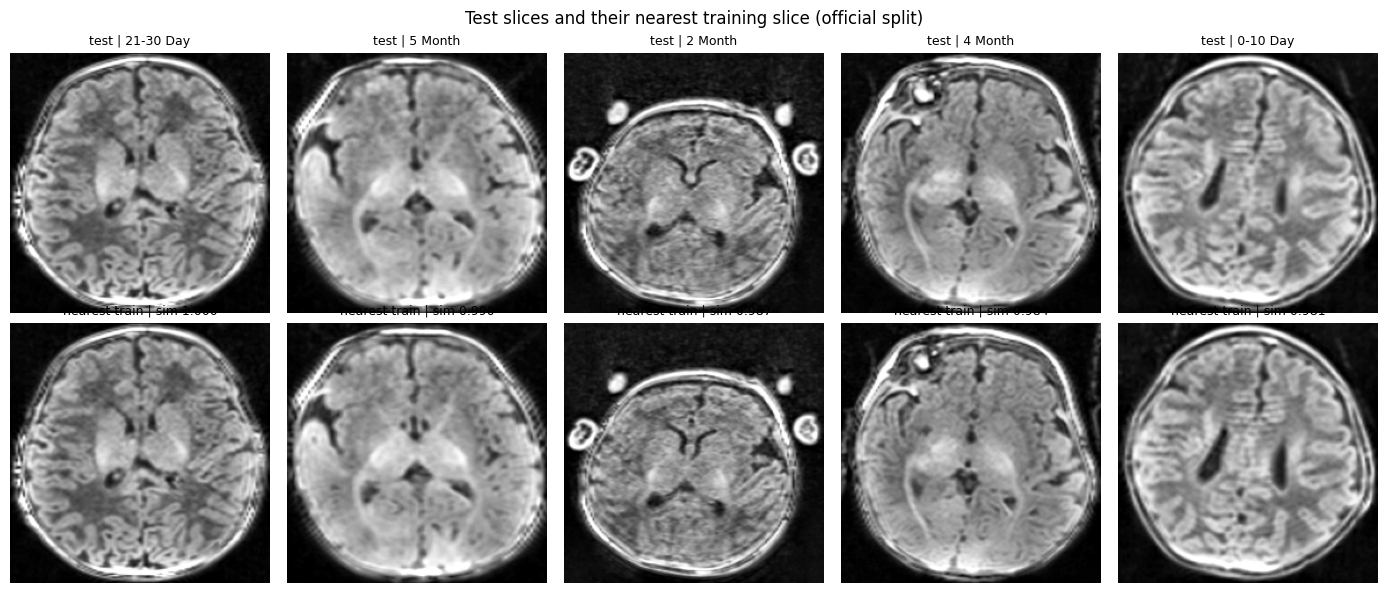

 thr  n_groups  largest_group_pct  test_sim>0.95_pct  test_sim_median
0.02     10372              0.522             57.708            0.958
0.05      2793              0.641              2.376            0.875
0.10      1016              2.282              0.847            0.843
0.15       480              3.822              0.020            0.852
0.20       240              4.036              0.111            0.847
0.30        68              4.708              0.000            0.857
0.40        34              4.727              1.679            0.843
0.50        31              4.727              0.000            0.842
Chosen GROUP_THR = 0.1
1016 groups | median size 2 | largest 363 (2.3% of data)
grouped split train/val/test: 10740 2451 2717
[grouped split] test->train nearest-neighbour cosine sim: median 0.843 | p90 0.904 | >0.95: 0.8% | >0.98: 0.7% | exact duplicates: 17


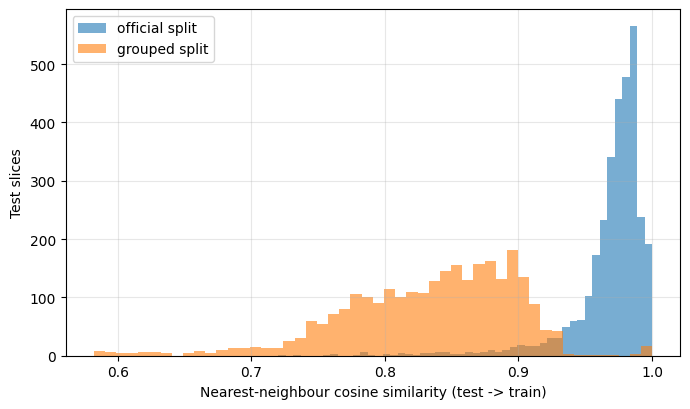

              feature  spearman_rho_vs_age
      brain_area_frac                0.240
tissue2_rel_intensity                0.200
         intensity_cv                0.197
         tissue1_frac                0.155
tissue3_rel_intensity                0.149
  bright_to_dark_area               -0.116
         tissue3_frac               -0.069
 bright_dark_contrast                0.059
tissue1_rel_intensity               -0.052
         tissue2_frac               -0.020


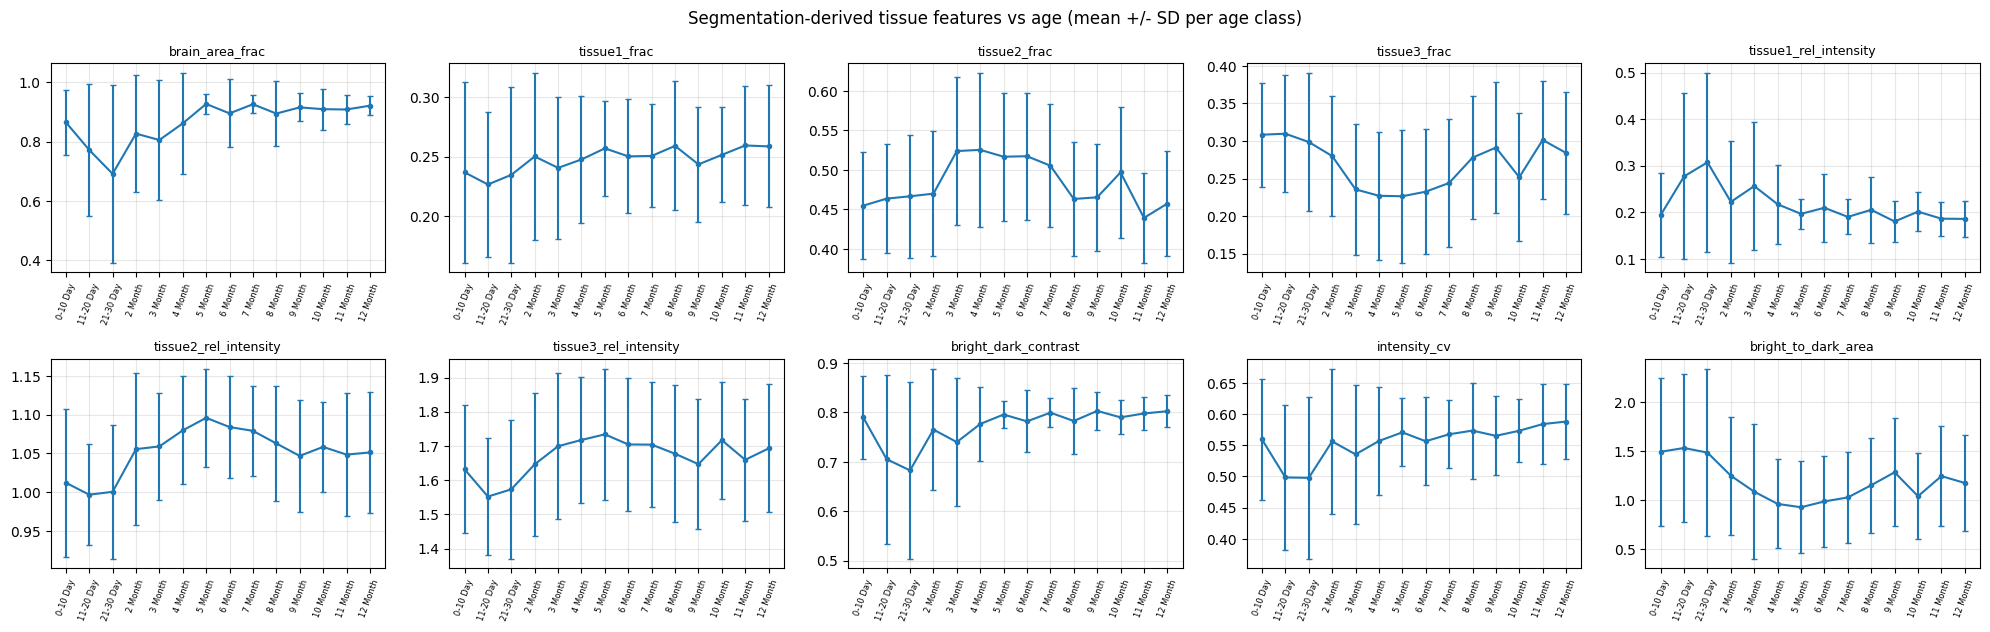


Tissue features ONLY (no CNN):
   split    acc  macro_f1  within1  mae_months
official 0.5814    0.5789   0.7119      2.1274
 grouped 0.1991    0.1960   0.4317      2.3999
[grouped] fold 0: train 10740 / val 2451 / test 2717 | group overlap train/test: 0
[grouped] fold 1: train 11005 / val 2076 / test 2827 | group overlap train/test: 0
[grouped] fold 2: train 10342 / val 2955 / test 2611 | group overlap train/test: 0
[grouped] fold 3: train 10093 / val 2153 / test 3662 | group overlap train/test: 0
[grouped] fold 4: train 9574 / val 2243 / test 4091 | group overlap train/test: 0

=== grouped fold 1/5 | V0 classification only ===
  [V0 classification only | grouped_fold0] ep 01 | loss 1.8981 | val acc 0.2354 F1 0.2040 MAE 1.110 mo
  [V0 classification only | grouped_fold0] ep 02 | loss 1.4876 | val acc 0.2448 F1 0.2193 MAE 1.189 mo
  [V0 classification only | grouped_fold0] ep 03 | loss 1.0234 | val acc 0.2550 F1 0.2284 MAE 1.177 mo
  [V0 classification only | grouped_fold0] ep 04 | lo

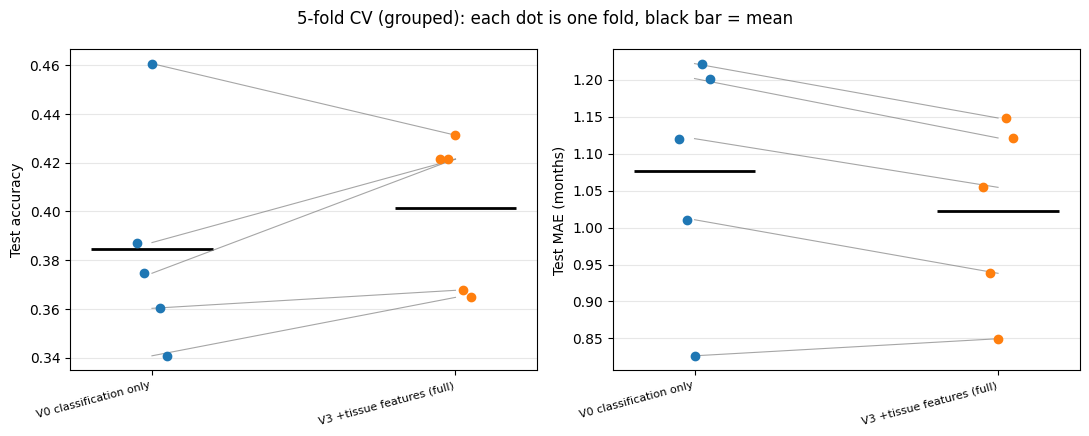

In [23]:
# %% PRE: check what the earlier notebook cells must have defined
import random
_need = ["df", "X", "Y", "P", "K", "class_order", "n_classes", "train_idx", "val_idx", "test_idx",
         "CFG", "device", "AMP", "OUT", "SEED", "augment_pair", "conv_block", "timm"]
_miss = [n for n in _need if n not in globals()]
if _miss:
    raise RuntimeError(f"Run the earlier notebook cells first. Missing: {_miss}")

# %% CELL 0: setup
import re, copy, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 12            # joint-model epochs per run (your classifiers plateaued around epoch 11)
W_SEG, W_REG = 0.5, 0.2
NSEG = K + 1

labels_all = df["label"].to_numpy()
class_months = df.groupby("label")["age_months"].first().sort_index().to_numpy().astype(np.float32)
MONTHS = class_months[labels_all]                       # age in months per image (class midpoint)
print("class -> months:", dict(zip(class_order, class_months.round(2))))

# segmentation targets: use the cleaned labels if you ran seg_improvements.py, else the original ones
SEG = Y2 if "Y2" in globals() else Y
LABEL_OK = label_ok if "label_ok" in globals() else np.ones(len(df), bool)
print("Segmentation labels from:", "Y2 (cleaned)" if "Y2" in globals() else "Y (original)",
      "| flagged images ignored for seg loss:", int((~LABEL_OK).sum()))

# %% CELL 1 (Part 4): leakage-aware evaluation
# 1a) Look at your filenames first. If they contain a subject/patient ID, set SUBJECT_REGEX to extract it
#     (one capture group) and the clustering below is skipped.
print(df["path"].head(8).apply(lambda p: "/".join(p.split("/")[-3:])).to_string())
SUBJECT_REGEX = None            # e.g. r"(P\d+)_"   or   r"^(\d+)_"

# 1b) cheap image fingerprint: 32x32, mean-centred, L2-normalised
import cv2
Z = np.stack([cv2.resize(x, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() for x in X])
Z -= Z.mean(1, keepdims=True); Z /= (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-6)

def nn_similarity(q_idx, r_idx, chunk=512):
    """Max cosine similarity (and argmax) from each query slice to any reference slice."""
    R = Z[r_idx]; best, arg = [], []
    for i in range(0, len(q_idx), chunk):
        S = Z[q_idx[i:i + chunk]] @ R.T
        best.append(S.max(1)); arg.append(r_idx[S.argmax(1)])
    return np.concatenate(best), np.concatenate(arg)

def exact_duplicates(q_idx, r_idx):
    h = {hashlib.md5(X[j].tobytes()).hexdigest() for j in r_idx}
    return int(sum(hashlib.md5(X[j].tobytes()).hexdigest() in h for j in q_idx))

def leakage_report(tr, te, name):
    s, _ = nn_similarity(te, tr)
    print(f"[{name}] test->train nearest-neighbour cosine sim: median {np.median(s):.3f} | "
          f"p90 {np.percentile(s, 90):.3f} | >0.95: {100*(s>0.95).mean():.1f}% | >0.98: {100*(s>0.98).mean():.1f}% "
          f"| exact duplicates: {exact_duplicates(te, tr)}")
    return s

s_official = leakage_report(np.concatenate([train_idx, val_idx]), test_idx, "official slice-level split")

# show a few test slices next to their nearest training slice
sim, nn_idx = nn_similarity(test_idx, train_idx)
pick = np.argsort(-sim)[np.linspace(0, len(sim) // 3, 5).astype(int)]
fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for k, p in enumerate(pick):
    ax[0, k].imshow(X[test_idx[p]], cmap="gray"); ax[0, k].set_title(f"test | {df.age_class[test_idx[p]]}", fontsize=9)
    ax[1, k].imshow(X[nn_idx[p]], cmap="gray"); ax[1, k].set_title(f"nearest train | sim {sim[p]:.3f}", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.suptitle("Test slices and their nearest training slice (official split)"); plt.tight_layout()
plt.savefig(OUT / "leakage_nearest_neighbours.png", dpi=200); plt.show()

# 1c) subject-like groups. Over-splitting a subject is the dangerous error (it leaves leakage in place),
#     so we use single linkage: any chain of near-identical slices ends up in ONE group.
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path
GROUP_LINKAGE = "single"
GROUP_THR_OVERRIDE = None       # set e.g. 0.15 to force a cosine-distance threshold after looking at the sweep below

def build_groups(thr, linkage=GROUP_LINKAGE):
    if SUBJECT_REGEX:
        ids = df["path"].apply(lambda p: (re.search(SUBJECT_REGEX, Path(p).name) or [None, Path(p).name])[1])
        return pd.factorize(ids)[0]
    groups = np.full(len(df), -1); nxt = 0
    for _, ids in df.groupby(["age_class", "sex"]).indices.items():   # a subject has one sex, ~one age class
        D = np.clip(1.0 - Z[ids] @ Z[ids].T, 0, 2)
        try:
            cl = AgglomerativeClustering(n_clusters=None, metric="precomputed", linkage=linkage, distance_threshold=thr)
        except TypeError:
            cl = AgglomerativeClustering(n_clusters=None, affinity="precomputed", linkage=linkage, distance_threshold=thr)
        lab = cl.fit_predict(D)
        groups[ids] = lab + nxt; nxt += lab.max() + 1
    return groups

def grouped_split(groups):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    rest, te = next(sgkf.split(np.zeros(len(df)), labels_all, groups))
    sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
    tr_i, va_i = next(sgkf2.split(np.zeros(len(rest)), labels_all[rest], groups[rest]))
    return rest[tr_i], rest[va_i], te

# sweep the distance threshold: pick the smallest value where test->train near-duplicates disappear
# but no single group swallows a large part of the data
sweep = []
for thr in [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    g = build_groups(thr); gsz = pd.Series(g).value_counts()
    a, b, c = grouped_split(g)
    s, _ = nn_similarity(c, np.concatenate([a, b]))
    sweep.append({"thr": thr, "n_groups": len(gsz), "largest_group_pct": 100 * gsz.max() / len(df),
                  "test_sim>0.95_pct": 100 * (s > 0.95).mean(), "test_sim_median": float(np.median(s))})
sweep = pd.DataFrame(sweep).round(3); print(sweep.to_string(index=False))
sweep.to_csv(OUT / "group_threshold_sweep.csv", index=False)
cap = sweep[sweep["largest_group_pct"] <= 15]
good = cap[cap["test_sim>0.95_pct"] <= 2.0]
GROUP_THR = (GROUP_THR_OVERRIDE if GROUP_THR_OVERRIDE is not None
             else float(good["thr"].iloc[0]) if len(good) else float(cap["thr"].iloc[-1]) if len(cap) else float(sweep["thr"].iloc[0]))
print("Chosen GROUP_THR =", GROUP_THR)

GROUPS = build_groups(GROUP_THR)
gs = pd.Series(GROUPS).value_counts()
print(f"{len(gs)} groups | median size {int(gs.median())} | largest {int(gs.max())} ({100*gs.max()/len(df):.1f}% of data)")

# 1d) grouped train / val / test split over ALL slices (official split ignored; groups never straddle splits)
g_train_idx, g_val_idx, g_test_idx = grouped_split(GROUPS)
assert not (set(GROUPS[g_train_idx]) & set(GROUPS[g_test_idx])) and not (set(GROUPS[g_val_idx]) & set(GROUPS[g_test_idx]))
print("grouped split train/val/test:", len(g_train_idx), len(g_val_idx), len(g_test_idx))
s_grouped = leakage_report(np.concatenate([g_train_idx, g_val_idx]), g_test_idx, "grouped split")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(s_official, bins=50, alpha=.6, label="official split"); ax.hist(s_grouped, bins=50, alpha=.6, label="grouped split")
ax.set_xlabel("Nearest-neighbour cosine similarity (test -> train)"); ax.set_ylabel("Test slices"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "leakage_similarity_hist.png", dpi=200); plt.show()

SPLITS = {"official": (train_idx, val_idx, test_idx), "grouped": (g_train_idx, g_val_idx, g_test_idx)}

# %% CELL 2 (Part 3): interpretable tissue features from the segmentation masks
FEAT_NAMES = (["brain_area_frac"] + [f"tissue{k}_frac" for k in range(1, K + 1)]
              + [f"tissue{k}_rel_intensity" for k in range(1, K + 1)]
              + ["bright_dark_contrast", "intensity_cv", "bright_to_dark_area"])

def tissue_features(img, pm, K=K):
    mask = pm > 0; nb = int(mask.sum())
    if nb < 100:
        return np.zeros(len(FEAT_NAMES), np.float32)
    xs = img.astype(np.float32); mean_all = xs[mask].mean() + 1e-6
    fr = [float((pm == k).sum()) / nb for k in range(1, K + 1)]
    mk = [float(xs[pm == k].mean()) / mean_all if (pm == k).any() else 0.0 for k in range(1, K + 1)]
    contrast = (mk[-1] - mk[0]) / (mk[-1] + mk[0] + 1e-6)
    return np.array([nb / pm.size, *fr, *mk, contrast, float(xs[mask].std()) / mean_all, fr[-1] / (fr[0] + 1e-6)], np.float32)

FEATS_RAW = np.stack([tissue_features(X[i], P[i]) for i in range(len(X))])
feat_df = pd.DataFrame(FEATS_RAW, columns=FEAT_NAMES); feat_df["age_months"] = MONTHS; feat_df["age_class"] = df["age_class"].values
feat_df.to_csv(OUT / "tissue_features.csv", index=False)

# correlation with age
from scipy.stats import spearmanr
corr = pd.DataFrame({"feature": FEAT_NAMES,
                     "spearman_rho_vs_age": [spearmanr(FEATS_RAW[:, j], MONTHS)[0] for j in range(len(FEAT_NAMES))]})
corr = corr.reindex(corr["spearman_rho_vs_age"].abs().sort_values(ascending=False).index).round(3)
print(corr.to_string(index=False)); corr.to_csv(OUT / "feature_age_correlation.csv", index=False)

# feature trajectories across the 14 age classes (mean +/- SD)
ncol = 5; nrow = int(np.ceil(len(FEAT_NAMES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.2 * nrow)); axes = axes.ravel()
for a, name in zip(axes, FEAT_NAMES):
    g = feat_df.groupby("age_class")[name].agg(["mean", "std"]).loc[class_order]
    a.errorbar(range(n_classes), g["mean"], yerr=g["std"], fmt="-o", ms=3, capsize=2)
    a.set_title(name, fontsize=9); a.set_xticks(range(n_classes)); a.set_xticklabels(class_order, rotation=70, fontsize=6); a.grid(alpha=.3)
for a in axes[len(FEAT_NAMES):]:
    a.axis("off")
plt.suptitle("Segmentation-derived tissue features vs age (mean +/- SD per age class)"); plt.tight_layout()
plt.savefig(OUT / "feature_trajectories.png", dpi=200); plt.show()

# how much age information do these few interpretable numbers carry on their own?
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
def feature_baseline(tr, te, name):
    clf = HistGradientBoostingClassifier(random_state=SEED).fit(FEATS_RAW[tr], labels_all[tr])
    reg = HistGradientBoostingRegressor(random_state=SEED).fit(FEATS_RAW[tr], MONTHS[tr])
    pc = clf.predict(FEATS_RAW[te]); y = labels_all[te]
    return {"split": name, "acc": accuracy_score(y, pc), "macro_f1": f1_score(y, pc, average="macro"),
            "within1": float(np.mean(np.abs(pc - y) <= 1)),
            "mae_months": float(np.mean(np.abs(reg.predict(FEATS_RAW[te]) - MONTHS[te])))}
feat_only = pd.DataFrame([feature_baseline(np.concatenate([a, b]), c, n) for n, (a, b, c) in SPLITS.items()]).round(4)
print("\nTissue features ONLY (no CNN):"); print(feat_only.to_string(index=False))
feat_only.to_csv(OUT / "features_only_baseline.csv", index=False)

# %% CELL 3 (Parts 1 + 2): joint multi-task network with classification / ordinal / regression heads
def seg_loss_ign(lg, y):
    valid = y != 255
    if valid.sum() == 0:
        return lg.sum() * 0.0
    ce = F.cross_entropy(lg, y, ignore_index=255)
    yy = y.clone(); yy[~valid] = 0
    p = lg.softmax(1) * valid.unsqueeze(1)
    oh = F.one_hot(yy, lg.shape[1]).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
    inter = (p * oh).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return 0.5 * ce + 0.5 * (1 - ((2 * inter + 1e-6) / (den + 1e-6)).mean())

class JointNet(nn.Module):
    """Shared CNN encoder -> (U-Net decoder for segmentation) + (pooled head(s) for age)."""
    def __init__(self, encoder, n_seg, n_cls, n_feats=0, heads=("ce",), pretrained=True, drop=0.2):
        super().__init__()
        try:
            self.enc = timm.create_model(encoder, pretrained=pretrained, features_only=True, in_chans=1)
        except Exception as e:
            print("Pretrained weights unavailable, using random init:", repr(e)[:100])
            self.enc = timm.create_model(encoder, pretrained=False, features_only=True, in_chans=1)
        chs = self.enc.feature_info.channels()
        self.blocks = nn.ModuleList(); c = chs[-1]
        for skip_c in reversed(chs[:-1]):
            self.blocks.append(conv_block(c + skip_c, skip_c)); c = skip_c
        self.seg_head = nn.Sequential(nn.Conv2d(c, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32),
                                      nn.ReLU(inplace=True), nn.Conv2d(32, n_seg, 1))
        self.n_feats = n_feats
        self.fmlp = nn.Sequential(nn.Linear(n_feats, 64), nn.ReLU(inplace=True)) if n_feats else None
        d = chs[-1] + (64 if n_feats else 0)
        self.drop = nn.Dropout(drop)
        self.heads = nn.ModuleDict()
        if "ce" in heads:  self.heads["ce"] = nn.Linear(d, n_cls)
        if "ord" in heads: self.heads["ord"] = nn.Linear(d, n_cls - 1)     # P(age > k), k = 0..K-2
        if "reg" in heads: self.heads["reg"] = nn.Linear(d, 1)             # age in months

    def forward(self, x, f=None, want_seg=True):
        H, W = x.shape[-2:]
        feats = self.enc((x - 0.45) / 0.225)
        z = feats[-1].mean((2, 3))
        if self.fmlp is not None:
            z = torch.cat([z, self.fmlp(f)], 1)
        z = self.drop(z)
        out = {k: h(z) for k, h in self.heads.items()}
        if want_seg:
            y = feats[-1]
            for blk, skip in zip(self.blocks, reversed(feats[:-1])):
                y = F.interpolate(y, size=skip.shape[-2:], mode="bilinear", align_corners=False)
                y = blk(torch.cat([y, skip], 1))
            y = F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)
            out["seg"] = self.seg_head(y)
        return out

class JointDS(Dataset):
    def __init__(self, idx, train, fe=None):
        self.idx, self.train, self.fe = idx, train, fe
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = X[j]; lab = SEG[j] if LABEL_OK[j] else np.full(X[j].shape, 255, np.uint8)
        if self.train:
            img, lab = augment_pair(img, lab)
        f = torch.from_numpy(self.fe[j]) if self.fe is not None else torch.zeros(1)
        return (torch.from_numpy(img).float().div(255).unsqueeze(0), torch.from_numpy(lab).long(),
                int(labels_all[j]), float(MONTHS[j]), f)

def joint_loss(out, seg, y, mo, seg_w):
    loss = 0.0
    if "ce" in out:  loss = loss + F.cross_entropy(out["ce"].float(), y, label_smoothing=0.1)
    if "ord" in out:
        tgt = (y.unsqueeze(1) > torch.arange(n_classes - 1, device=y.device).unsqueeze(0)).float()
        loss = loss + F.binary_cross_entropy_with_logits(out["ord"].float(), tgt)
    if "reg" in out: loss = loss + W_REG * F.l1_loss(out["reg"].float().squeeze(1), mo)
    if seg_w > 0 and "seg" in out: loss = loss + seg_w * seg_loss_ign(out["seg"].float(), seg)
    return loss

def metrics_from(pred_cls, y, pred_months=None):
    pm = class_months[pred_cls] if pred_months is None else pred_months
    return {"acc": accuracy_score(y, pred_cls), "macro_f1": f1_score(y, pred_cls, average="macro"),
            "within1": float(np.mean(np.abs(pred_cls - y) <= 1)), "mae_months": float(np.mean(np.abs(pm - class_months[y])))}

@torch.no_grad()
def eval_joint(model, idx, fe, use_seg, bs=64):
    loader = DataLoader(JointDS(idx, False, fe), batch_size=bs, shuffle=False, num_workers=2, pin_memory=AMP)
    model.eval(); buf = {"ce": [], "ord": [], "reg": []}; ys = []
    tp = np.zeros(NSEG); fp = np.zeros(NSEG); fn = np.zeros(NSEG)
    for x, seg, y, mo, f in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            out = model(x, f.to(device) if model.n_feats else None, want_seg=use_seg)
        for k in buf:
            if k in out: buf[k].append(out[k].float().cpu())
        ys.append(y)
        if use_seg:
            pred = out["seg"].argmax(1).cpu(); valid = seg != 255
            for c in range(NSEG):
                tp[c] += ((pred == c) & (seg == c) & valid).sum().item()
                fp[c] += ((pred == c) & (seg != c) & valid).sum().item()
                fn[c] += ((pred != c) & (seg == c) & valid).sum().item()
    y = torch.cat(ys).numpy(); res = {"y": y}
    if buf["ce"]:
        lg = torch.cat(buf["ce"]); res["ce"] = metrics_from(lg.argmax(1).numpy(), y); res["ce"]["probs"] = lg.softmax(1).numpy()
    if buf["ord"]:
        res["ord"] = metrics_from((torch.cat(buf["ord"]).sigmoid() > 0.5).sum(1).numpy(), y)
    if buf["reg"]:
        m = torch.cat(buf["reg"]).squeeze(1).numpy()
        res["reg"] = metrics_from(np.abs(m[:, None] - class_months[None]).argmin(1), y, m)
    if use_seg:
        res["seg_dice"] = float(((2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7))[1:].mean())
    return res

def run_experiment(vname, cfg, split, epochs=EPOCHS, track_test=False):
    tr_idx, va_idx, te_idx = SPLITS[split]
    heads, seg_w, use_f = cfg["heads"], cfg["seg_w"], cfg["feats"]
    fe = None
    if use_f:
        mu, sd = FEATS_RAW[tr_idx].mean(0), FEATS_RAW[tr_idx].std(0) + 1e-6
        fe = ((FEATS_RAW - mu) / sd).astype(np.float32)
    use_seg = seg_w > 0; primary = heads[0]
    model = JointNet(CFG["seg_encoder"], NSEG, n_classes, FEATS_RAW.shape[1] if use_f else 0, heads, CFG["pretrained"]).to(device)
    tr = DataLoader(JointDS(tr_idx, True, fe), batch_size=CFG["batch_size"], shuffle=True,
                    num_workers=2, pin_memory=AMP, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, epochs=epochs, steps_per_epoch=len(tr), pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    hist = []; best, best_w, best_ep = -1, None, 0
    for ep in range(epochs):
        model.train(); tl = 0.0
        for x, seg, y, mo, f in tr:
            x, seg, y, mo = x.to(device), seg.to(device), y.to(device), mo.float().to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=AMP):
                out = model(x, f.to(device) if use_f else None, want_seg=use_seg)
                loss = joint_loss(out, seg, y, mo, seg_w)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tl += loss.item()
        v = eval_joint(model, va_idx, fe, use_seg)
        row = {"epoch": ep + 1, "train_loss": tl / len(tr), "val_acc": v[primary]["acc"],
               "val_macro_f1": v[primary]["macro_f1"], "val_mae_months": v[primary]["mae_months"],
               "val_seg_dice": v.get("seg_dice", np.nan)}
        if track_test:
            t = eval_joint(model, te_idx, fe, use_seg)
            row.update(test_acc=t[primary]["acc"], test_macro_f1=t[primary]["macro_f1"], test_mae_months=t[primary]["mae_months"])
        hist.append(row)
        if v[primary]["macro_f1"] > best:                          # selection uses VALIDATION only
            best, best_w, best_ep = v[primary]["macro_f1"], copy.deepcopy(model.state_dict()), ep + 1
        print(f"  [{vname} | {split}] ep {ep+1:02d} | loss {row['train_loss']:.4f} | val acc {row['val_acc']:.4f} "
              f"F1 {row['val_macro_f1']:.4f} MAE {row['val_mae_months']:.3f} mo")
    model.load_state_dict(best_w)
    test = eval_joint(model, te_idx, fe, use_seg)
    slug = re.sub(r"[^A-Za-z0-9]+", "_", f"{vname}_{split}")
    torch.save(model.state_dict(), OUT / f"joint_{slug}.pt")
    del model, opt; torch.cuda.empty_cache()
    return {"hist": pd.DataFrame(hist), "test": test, "best_val": best, "best_epoch": best_ep, "primary": primary}

# %% K-FOLD CELL 1: settings + fold construction
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

_required = ["GROUPS", "FEATS_RAW", "run_experiment", "SPLITS", "df",
             "labels_all", "SEED", "OUT", "W_SEG"]
_missing = [n for n in _required if n not in globals()]
if _missing:
    raise RuntimeError(f"Novelty setup did not run. Missing: {_missing}")

N_FOLDS = 5
KF_EPOCHS = 10                    # per fold; 5 folds x variants x epochs adds up
KF_MODES = ["grouped"]            # add "slice" for the leaky slice-level comparison
KF_VARIANTS = ["V0 classification only", "V3 +tissue features (full)"]

VARIANTS = {
    "V0 classification only":     dict(heads=("ce",),              seg_w=0.0,   feats=False),
    "V1 +ordinal +regression":    dict(heads=("ce", "ord", "reg"), seg_w=0.0,   feats=False),
    "V2 +joint segmentation":     dict(heads=("ce", "ord", "reg"), seg_w=W_SEG, feats=False),
    "V3 +tissue features (full)": dict(heads=("ce", "ord", "reg"), seg_w=W_SEG, feats=True),
}

GROUPS = np.asarray(GROUPS); labels_all = np.asarray(labels_all)

def make_folds(mode):
    """List of (train_idx, val_idx, test_idx). 'grouped' never splits a group across sets."""
    n = len(df)
    Splitter = StratifiedGroupKFold if mode == "grouped" else StratifiedKFold
    def split(idx, n_splits):
        kw = dict(n_splits=n_splits, shuffle=True, random_state=SEED)
        if mode == "grouped":
            return Splitter(**kw).split(np.zeros(len(idx)), labels_all[idx], GROUPS[idx])
        return Splitter(**kw).split(np.zeros(len(idx)), labels_all[idx])
    folds = []
    for rest, te in split(np.arange(n), N_FOLDS):
        tr_i, va_i = next(iter(split(rest, 6)))
        folds.append((rest[tr_i], rest[va_i], te))
    return folds

FOLDS = {m: make_folds(m) for m in KF_MODES}
for m, fl in FOLDS.items():
    for k, (a, b, c) in enumerate(fl):
        extra = ""
        if m == "grouped":
            assert not (set(GROUPS[a]) & set(GROUPS[c])) and not (set(GROUPS[b]) & set(GROUPS[c])), "group leakage!"
            extra = " | group overlap train/test: 0"
        print(f"[{m}] fold {k}: train {len(a)} / val {len(b)} / test {len(c)}{extra}")

# %% K-FOLD CELL 2: run every fold (resumable, even after a kernel restart)
CSV = OUT / "kfold_per_fold.csv"
KF_ROWS = {}                                              # (mode, variant, fold, readout) -> row dict
if CSV.exists():
    for r in pd.read_csv(CSV).to_dict("records"):
        KF_ROWS[(r["mode"], r["variant"], int(r["fold"]), r["readout"])] = r

def save_rows():
    pd.DataFrame(list(KF_ROWS.values())).round(4).to_csv(CSV, index=False)

def add_result(mode, vname, k, res):
    for ro in ("ce", "ord", "reg"):
        if ro in res["test"]:
            m = res["test"][ro]
            KF_ROWS[(mode, vname, k, ro)] = {
                "mode": mode, "variant": vname, "fold": k, "readout": ro, "acc": m["acc"],
                "macro_f1": m["macro_f1"], "within1": m["within1"], "mae_months": m["mae_months"],
                "best_epoch": res["best_epoch"], "val_macro_f1": res["best_val"],
                "test_seg_dice": res["test"].get("seg_dice", np.nan)}

for mode in KF_MODES:
    for k, split in enumerate(FOLDS[mode]):
        SPLITS[f"{mode}_fold{k}"] = split
        for vname in KF_VARIANTS:
            if (mode, vname, k, "ce") in KF_ROWS:         # already finished
                continue
            print(f"\n=== {mode} fold {k + 1}/{N_FOLDS} | {vname} ===")
            res = run_experiment(vname, VARIANTS[vname], f"{mode}_fold{k}", epochs=KF_EPOCHS)
            add_result(mode, vname, k, res)
            save_rows()                                   # progress survives a crash

# %% K-FOLD CELL 3: aggregate, paired comparison, plot
from scipy import stats
kf = pd.read_csv(CSV)

def fmt_pm(s, d=4):
    return f"{s.mean():.{d}f} +/- {s.std(ddof=1):.{d}f}"

summary = (kf.groupby(["mode", "variant", "readout"])
             .agg(folds=("fold", "nunique"), acc=("acc", fmt_pm), macro_f1=("macro_f1", fmt_pm),
                  within1=("within1", fmt_pm), mae_months=("mae_months", lambda s: fmt_pm(s, 3)))
             .reset_index())
print(summary.to_string(index=False)); summary.to_csv(OUT / "kfold_summary.csv", index=False)

base, comp = KF_VARIANTS[0], []
for mode in KF_MODES:
    sel = lambda v: kf[(kf["mode"] == mode) & (kf["variant"] == v) & (kf["readout"] == "ce")].set_index("fold")
    b = sel(base)
    for v in KF_VARIANTS[1:]:
        c = sel(v); common = b.index.intersection(c.index)
        if len(common) < 2:
            continue
        for metric in ("acc", "macro_f1", "mae_months"):
            d = (c.loc[common, metric] - b.loc[common, metric]).to_numpy()
            p = stats.ttest_rel(c.loc[common, metric], b.loc[common, metric]).pvalue if len(common) > 2 else np.nan
            comp.append({"mode": mode, "comparison": f"{v} minus {base}", "metric": metric,
                         "folds": len(common), "mean_diff": d.mean(), "sd_diff": d.std(ddof=1), "paired_t_p": p})
comp = pd.DataFrame(comp).round(4)
if len(comp):
    print("\nPaired differences (positive acc/F1 = better; negative MAE = better):")
    print(comp.to_string(index=False)); comp.to_csv(OUT / "kfold_paired.csv", index=False)

for mode in KF_MODES:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    sub = kf[(kf["mode"] == mode) & (kf["readout"] == "ce")]
    for a, metric, lab in zip(ax, ("acc", "mae_months"), ("Test accuracy", "Test MAE (months)")):
        for i, v in enumerate(KF_VARIANTS):
            y = sub[sub["variant"] == v].sort_values("fold")[metric].to_numpy()
            a.scatter(np.full(len(y), i) + np.linspace(-.05, .05, len(y)), y, zorder=3)
            a.hlines(y.mean(), i - .2, i + .2, color="k", lw=2)
        wide = sub.pivot(index="fold", columns="variant", values=metric)[KF_VARIANTS].dropna()
        for _, row in wide.iterrows():
            a.plot(range(len(KF_VARIANTS)), row.to_numpy(), color="gray", lw=.8, alpha=.7)
        a.set_xticks(range(len(KF_VARIANTS))); a.set_xticklabels(KF_VARIANTS, rotation=15, ha="right", fontsize=8)
        a.set_ylabel(lab); a.grid(alpha=.3, axis="y")
    plt.suptitle(f"{N_FOLDS}-fold CV ({mode}): each dot is one fold, black bar = mean"); plt.tight_layout()
    plt.savefig(OUT / f"kfold_{mode}.png", dpi=200); plt.show()

In [25]:
import pandas as pd
kf = pd.read_csv(OUT / "kfold_per_fold.csv")

ce = kf[(kf["mode"] == "grouped") & (kf["readout"] == "ce")]
cols = ["acc", "macro_f1", "within1", "mae_months"]

# one row per fold, V0 and V3 side by side
wide = ce.pivot(index="fold", columns="variant", values=cols)
wide.index = [f"Fold {i + 1}" for i in wide.index]
wide.loc["Mean"] = wide.mean()
wide.loc["SD"] = wide.iloc[:-1].std(ddof=1)
print(wide.round(4).to_string())

wide.round(4).to_csv(OUT / "kfold_per_fold_table.csv")   # opens in Excel

                           acc                                          macro_f1                                           within1                                        mae_months                           
variant V0 classification only V3 +tissue features (full) V0 classification only V3 +tissue features (full) V0 classification only V3 +tissue features (full) V0 classification only V3 +tissue features (full)
Fold 1                  0.3872                     0.4214                 0.3717                     0.3924                 0.7372                     0.7435                 1.1203                     1.0544
Fold 2                  0.3746                     0.4216                 0.3562                     0.3978                 0.7128                     0.7025                 1.0106                     0.9381
Fold 3                  0.4607                     0.4313                 0.4162                     0.3859                 0.7951                     0.7664           

In [24]:
# Time per slice (training + inference) for segmentation and classification.
# Each "# %%" block is one cell. Run AFTER cells 11 and 13 of your notebook
# (needs TimmUNet, seg_loss, seg_train_loader, cls_loader, CFG, train_idx, device, AMP).

# %% CELL 1: benchmark helpers
import time, numpy as np, pandas as pd, torch, torch.nn as nn

def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def bench_train(model, loader, loss_fn, n_batches=40, warmup=5, lr=3e-4):
    """ms per slice for one optimisation step, split into GPU compute and data-loader wait."""
    model = model.to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    it = iter(loader); t_data = t_comp = 0.0; n = 0
    for b in range(n_batches + warmup):
        t0 = time.perf_counter()
        x, y = next(it)
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True); _sync()
        t1 = time.perf_counter()
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=AMP):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); _sync()
        t2 = time.perf_counter()
        if b >= warmup:                                   # skip warm-up (cuDNN autotune, allocator)
            t_data += t1 - t0; t_comp += t2 - t1; n += len(x)
    return {"compute_ms": 1e3 * t_comp / n, "data_wait_ms": 1e3 * t_data / n,
            "total_ms": 1e3 * (t_comp + t_data) / n}

@torch.no_grad()
def bench_infer(model, shape, bs=32, n_batches=50, warmup=5, n_single=100):
    model = model.to(device).eval()
    xb = torch.rand(bs, *shape, device=device)
    for _ in range(warmup):
        with torch.autocast(device_type=device.type, enabled=AMP): model(xb)
    _sync(); t0 = time.perf_counter()
    for _ in range(n_batches):
        with torch.autocast(device_type=device.type, enabled=AMP): model(xb)
    _sync(); batch_ms = 1e3 * (time.perf_counter() - t0) / (n_batches * bs)
    x1 = torch.rand(1, *shape, device=device)
    for _ in range(warmup):
        with torch.autocast(device_type=device.type, enabled=AMP): model(x1)
    _sync(); t0 = time.perf_counter()
    for _ in range(n_single):
        with torch.autocast(device_type=device.type, enabled=AMP): model(x1)
    _sync(); single_ms = 1e3 * (time.perf_counter() - t0) / n_single
    return {"infer_ms_batched": batch_ms, "infer_ms_single": single_ms}

# %% CELL 2: run for the segmentation model and every classifier
rows = []
n_train = len(train_idx)

def add_row(task, name, mode, model, loader, loss_fn, shape, epochs):
    params = sum(p.numel() for p in model.parameters()) / 1e6
    tr = bench_train(model, loader, loss_fn)
    inf = bench_infer(model, shape)
    ep_min = tr["total_ms"] * n_train / 1e3 / 60
    rows.append({"task": task, "model": name, "input": mode, "params_M": params,
                 "train_ms/slice (GPU)": tr["compute_ms"], "train_ms/slice (+data wait)": tr["total_ms"],
                 "est. min/epoch": ep_min, "epochs": epochs, "est. total train min": ep_min * epochs,
                 "infer_ms/slice (batch 32)": inf["infer_ms_batched"], "infer_ms/slice (single)": inf["infer_ms_single"]})
    del model; torch.cuda.empty_cache()

add_row("segmentation", CFG["seg_encoder"] + " U-Net", "gray 1ch",
        TimmUNet(CFG["seg_encoder"], N_SEG_CLASSES, False), seg_train_loader, seg_loss,
        (1, 224, 224), CFG["seg_epochs"])

for name in CFG["cls_models"]:
    for mode in ("baseline", "seg_guided"):
        add_row("classification", name, mode,
                timm.create_model(name, pretrained=False, num_classes=n_classes),
                cls_loader(train_idx, mode, True), nn.CrossEntropyLoss(label_smoothing=0.1),
                (3, 224, 224), CFG["cls_epochs"])

timing = pd.DataFrame(rows).round(2)
timing.to_csv(OUT / "time_per_slice.csv", index=False)
print("GPU:", torch.cuda.get_device_name(0) if AMP else "CPU", "| train slices:", n_train)
print(timing.to_string(index=False))

# %% CELL 3 (optional): measure a REAL training run instead of an estimate
# Wrap any existing training call, e.g.:
#   t0 = time.perf_counter()
#   r = train_classifier("swin_tiny_patch4_window7_224", "baseline", cls_epochs)
#   total = time.perf_counter() - t0
#   print(f"{total/60:.1f} min total | {1e3*total/(cls_epochs*len(train_idx)):.2f} ms per training slice per epoch")
# This includes validation passes, so it is slightly higher than the benchmark above.
# For segmentation use train_segmentation(seg_epochs) the same way.

# Preprocessing cost from your own notebook output (cell 5): 850 s for 15,908 images,
# i.e. about 53 ms per slice wall-clock with 8 threads (one-off cost, not per epoch).
print(f"Preprocessing: {850 / 15908 * 1e3:.1f} ms per slice (8 threads, one-off)")

GPU: Tesla T4 | train slices: 10818
          task                        model      input  params_M  train_ms/slice (GPU)  train_ms/slice (+data wait)  est. min/epoch  epochs  est. total train min  infer_ms/slice (batch 32)  infer_ms/slice (single)
  segmentation          convnext_tiny U-Net   gray 1ch     34.81                  8.56                         8.62            1.55      25                 38.86                       2.99                    10.66
classification                convnext_tiny   baseline     27.83                  5.17                         5.23            0.94      15                 14.13                       1.70                     9.13
classification                convnext_tiny seg_guided     27.83                  4.98                         5.04            0.91      15                 13.64                       1.61                     9.40
classification swin_tiny_patch4_window7_224   baseline     27.53                  6.18                      

class -> months: {'0-10 Day': np.float32(0.17), '11-20 Day': np.float32(0.52), '21-30 Day': np.float32(0.85), '2 Month': np.float32(2.0), '3 Month': np.float32(3.0), '4 Month': np.float32(4.0), '5 Month': np.float32(5.0), '6 Month': np.float32(6.0), '7 Month': np.float32(7.0), '8 Month': np.float32(8.0), '9 Month': np.float32(9.0), '10 Month': np.float32(10.0), '11 Month': np.float32(11.0), '12 Month': np.float32(12.0)}
Segmentation labels from: Y (original) | flagged images ignored for seg loss: 0
0      test/0-10 Day/0-10 Day_1.png
1     test/0-10 Day/0-10 Day_10.png
2    test/0-10 Day/0-10 Day_100.png
3    test/0-10 Day/0-10 Day_101.png
4    test/0-10 Day/0-10 Day_102.png
5    test/0-10 Day/0-10 Day_103.png
6    test/0-10 Day/0-10 Day_104.png
7    test/0-10 Day/0-10 Day_105.png
[official slice-level split] test->train nearest-neighbour cosine sim: median 0.976 | p90 0.990 | >0.95: 86.7% | >0.98: 39.8% | exact duplicates: 140


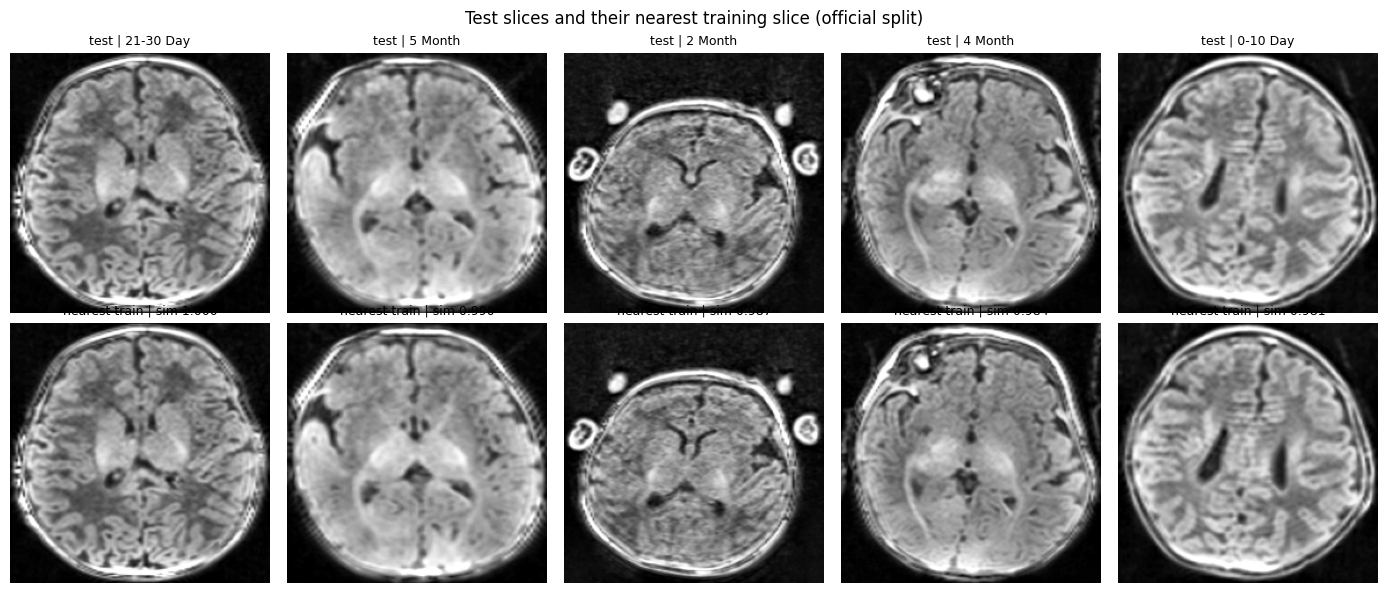

 thr  n_groups  largest_group_pct  test_sim>0.95_pct  test_sim_median
0.02     10372              0.522             57.708            0.958
0.05      2793              0.641              2.376            0.875
0.10      1016              2.282              0.847            0.843
0.15       480              3.822              0.020            0.852
0.20       240              4.036              0.111            0.847
0.30        68              4.708              0.000            0.857
0.40        34              4.727              1.679            0.843
0.50        31              4.727              0.000            0.842
Chosen GROUP_THR = 0.1
1016 groups | median size 2 | largest 363 (2.3% of data)
grouped split train/val/test: 10740 2451 2717
[grouped split] test->train nearest-neighbour cosine sim: median 0.843 | p90 0.904 | >0.95: 0.8% | >0.98: 0.7% | exact duplicates: 17


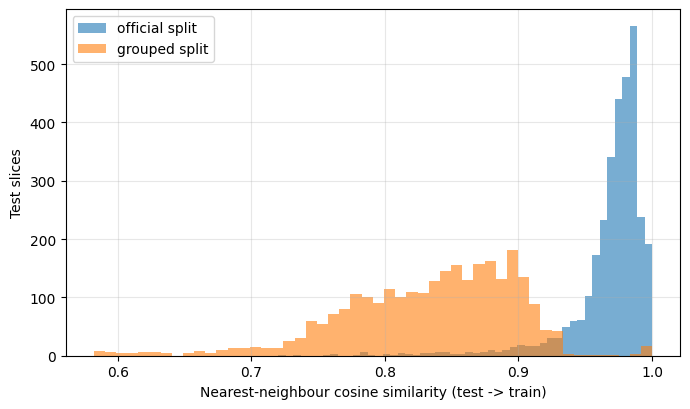

              feature  spearman_rho_vs_age
      brain_area_frac                0.240
tissue2_rel_intensity                0.200
         intensity_cv                0.197
         tissue1_frac                0.155
tissue3_rel_intensity                0.149
  bright_to_dark_area               -0.116
         tissue3_frac               -0.069
 bright_dark_contrast                0.059
tissue1_rel_intensity               -0.052
         tissue2_frac               -0.020


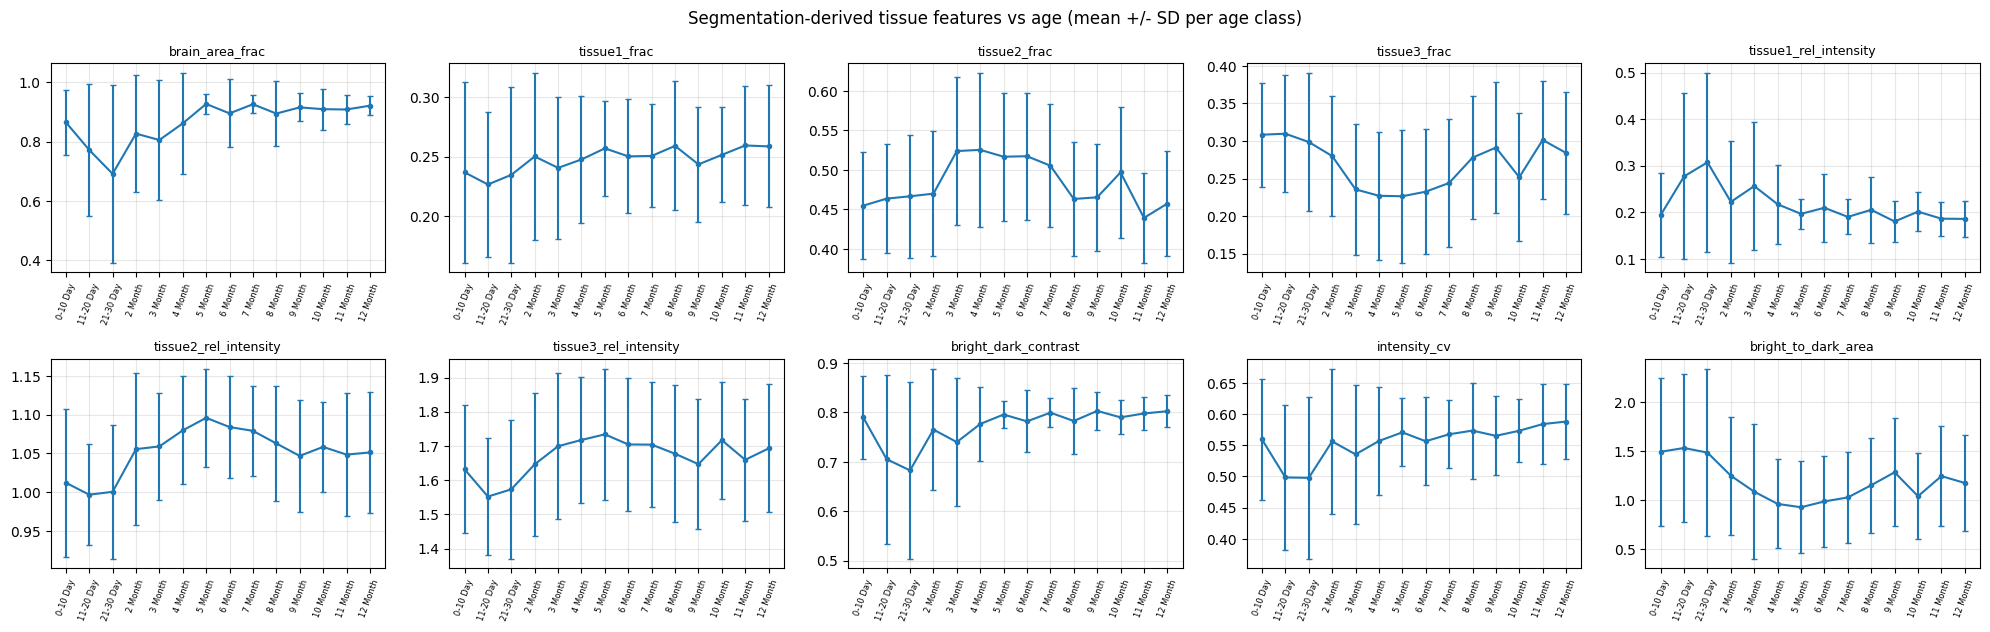


Tissue features ONLY (no CNN):
   split    acc  macro_f1  within1  mae_months
official 0.5814    0.5789   0.7119      2.1274
 grouped 0.1991    0.1960   0.4317      2.3999

=== V0 classification only | official split ===
  [V0 classification only | official] ep 01 | loss 2.0299 | val acc 0.4105 F1 0.3816 MAE 1.156 mo
  [V0 classification only | official] ep 02 | loss 1.6582 | val acc 0.5691 F1 0.5453 MAE 0.763 mo
  [V0 classification only | official] ep 03 | loss 1.3406 | val acc 0.7565 F1 0.7555 MAE 0.418 mo
  [V0 classification only | official] ep 04 | loss 1.0151 | val acc 0.8822 F1 0.8824 MAE 0.159 mo
  [V0 classification only | official] ep 05 | loss 0.8338 | val acc 0.9005 F1 0.8999 MAE 0.138 mo
  [V0 classification only | official] ep 06 | loss 0.7344 | val acc 0.9487 F1 0.9481 MAE 0.081 mo
  [V0 classification only | official] ep 07 | loss 0.6637 | val acc 0.9618 F1 0.9610 MAE 0.059 mo
  [V0 classification only | official] ep 08 | loss 0.6180 | val acc 0.9733 F1 0.9725 MAE 0.0

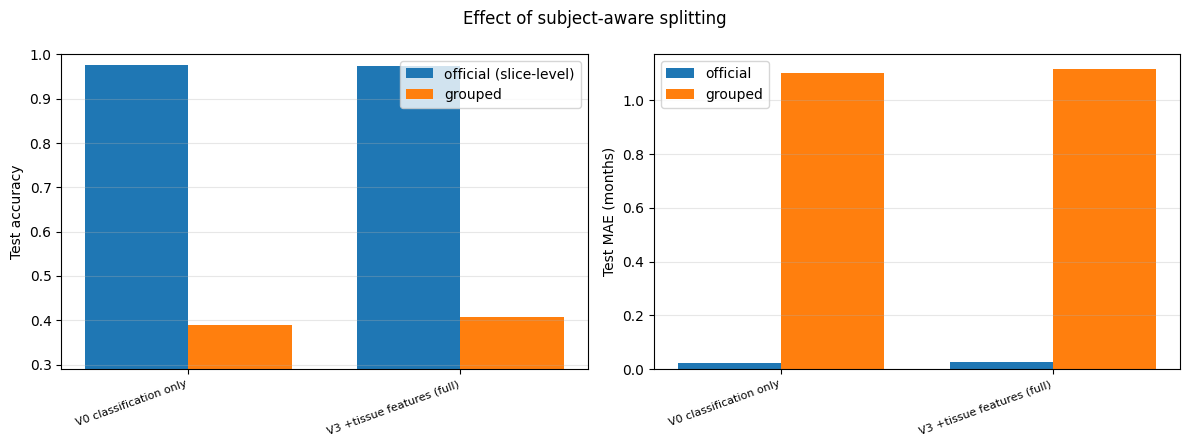

In [26]:
# Novelty experiments. Each "# %%" block is one notebook cell. Run them in order, AFTER your
# notebook cells up to cell 12 (needs: df, X, P, K, Y, class_order, n_classes, train_idx, val_idx,
# test_idx, CFG, device, AMP, OUT, SEED, augment_pair, conv_block, timm, torch, np, pd, plt).
#
# What this adds
#   Part 4  leakage-aware evaluation : near-duplicate diagnostic + subject-like groups + grouped split
#   Part 3  interpretable features   : tissue fractions / contrast from the segmentation, vs age
#   Part 1  ordinal + regression age : extra heads, MAE in months
#   Part 2  joint multi-task model   : one encoder, segmentation + age heads (+ optional feature fusion)

# %% CELL 0: setup
import re, copy, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 12            # joint-model epochs per run (your classifiers plateaued around epoch 11)
W_SEG, W_REG = 0.5, 0.2
NSEG = K + 1

labels_all = df["label"].to_numpy()
class_months = df.groupby("label")["age_months"].first().sort_index().to_numpy().astype(np.float32)
MONTHS = class_months[labels_all]                       # age in months per image (class midpoint)
print("class -> months:", dict(zip(class_order, class_months.round(2))))

# segmentation targets: use the cleaned labels if you ran seg_improvements.py, else the original ones
SEG = Y2 if "Y2" in globals() else Y
LABEL_OK = label_ok if "label_ok" in globals() else np.ones(len(df), bool)
print("Segmentation labels from:", "Y2 (cleaned)" if "Y2" in globals() else "Y (original)",
      "| flagged images ignored for seg loss:", int((~LABEL_OK).sum()))

# %% CELL 1 (Part 4): leakage-aware evaluation
# 1a) Look at your filenames first. If they contain a subject/patient ID, set SUBJECT_REGEX to extract it
#     (one capture group) and the clustering below is skipped.
print(df["path"].head(8).apply(lambda p: "/".join(p.split("/")[-3:])).to_string())
SUBJECT_REGEX = None            # e.g. r"(P\d+)_"   or   r"^(\d+)_"

# 1b) cheap image fingerprint: 32x32, mean-centred, L2-normalised
import cv2
Z = np.stack([cv2.resize(x, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() for x in X])
Z -= Z.mean(1, keepdims=True); Z /= (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-6)

def nn_similarity(q_idx, r_idx, chunk=512):
    """Max cosine similarity (and argmax) from each query slice to any reference slice."""
    R = Z[r_idx]; best, arg = [], []
    for i in range(0, len(q_idx), chunk):
        S = Z[q_idx[i:i + chunk]] @ R.T
        best.append(S.max(1)); arg.append(r_idx[S.argmax(1)])
    return np.concatenate(best), np.concatenate(arg)

def exact_duplicates(q_idx, r_idx):
    h = {hashlib.md5(X[j].tobytes()).hexdigest() for j in r_idx}
    return int(sum(hashlib.md5(X[j].tobytes()).hexdigest() in h for j in q_idx))

def leakage_report(tr, te, name):
    s, _ = nn_similarity(te, tr)
    print(f"[{name}] test->train nearest-neighbour cosine sim: median {np.median(s):.3f} | "
          f"p90 {np.percentile(s, 90):.3f} | >0.95: {100*(s>0.95).mean():.1f}% | >0.98: {100*(s>0.98).mean():.1f}% "
          f"| exact duplicates: {exact_duplicates(te, tr)}")
    return s

s_official = leakage_report(np.concatenate([train_idx, val_idx]), test_idx, "official slice-level split")

# show a few test slices next to their nearest training slice
sim, nn_idx = nn_similarity(test_idx, train_idx)
pick = np.argsort(-sim)[np.linspace(0, len(sim) // 3, 5).astype(int)]
fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for k, p in enumerate(pick):
    ax[0, k].imshow(X[test_idx[p]], cmap="gray"); ax[0, k].set_title(f"test | {df.age_class[test_idx[p]]}", fontsize=9)
    ax[1, k].imshow(X[nn_idx[p]], cmap="gray"); ax[1, k].set_title(f"nearest train | sim {sim[p]:.3f}", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.suptitle("Test slices and their nearest training slice (official split)"); plt.tight_layout()
plt.savefig(OUT / "leakage_nearest_neighbours.png", dpi=200); plt.show()

# 1c) subject-like groups. Over-splitting a subject is the dangerous error (it leaves leakage in place),
#     so we use single linkage: any chain of near-identical slices ends up in ONE group.
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path
GROUP_LINKAGE = "single"
GROUP_THR_OVERRIDE = None       # set e.g. 0.15 to force a cosine-distance threshold after looking at the sweep below

def build_groups(thr, linkage=GROUP_LINKAGE):
    if SUBJECT_REGEX:
        ids = df["path"].apply(lambda p: (re.search(SUBJECT_REGEX, Path(p).name) or [None, Path(p).name])[1])
        return pd.factorize(ids)[0]
    groups = np.full(len(df), -1); nxt = 0
    for _, ids in df.groupby(["age_class", "sex"]).indices.items():   # a subject has one sex, ~one age class
        D = np.clip(1.0 - Z[ids] @ Z[ids].T, 0, 2)
        try:
            cl = AgglomerativeClustering(n_clusters=None, metric="precomputed", linkage=linkage, distance_threshold=thr)
        except TypeError:
            cl = AgglomerativeClustering(n_clusters=None, affinity="precomputed", linkage=linkage, distance_threshold=thr)
        lab = cl.fit_predict(D)
        groups[ids] = lab + nxt; nxt += lab.max() + 1
    return groups

def grouped_split(groups):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    rest, te = next(sgkf.split(np.zeros(len(df)), labels_all, groups))
    sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
    tr_i, va_i = next(sgkf2.split(np.zeros(len(rest)), labels_all[rest], groups[rest]))
    return rest[tr_i], rest[va_i], te

# sweep the distance threshold: pick the smallest value where test->train near-duplicates disappear
# but no single group swallows a large part of the data
sweep = []
for thr in [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    g = build_groups(thr); gsz = pd.Series(g).value_counts()
    a, b, c = grouped_split(g)
    s, _ = nn_similarity(c, np.concatenate([a, b]))
    sweep.append({"thr": thr, "n_groups": len(gsz), "largest_group_pct": 100 * gsz.max() / len(df),
                  "test_sim>0.95_pct": 100 * (s > 0.95).mean(), "test_sim_median": float(np.median(s))})
sweep = pd.DataFrame(sweep).round(3); print(sweep.to_string(index=False))
sweep.to_csv(OUT / "group_threshold_sweep.csv", index=False)
cap = sweep[sweep["largest_group_pct"] <= 15]
good = cap[cap["test_sim>0.95_pct"] <= 2.0]
GROUP_THR = (GROUP_THR_OVERRIDE if GROUP_THR_OVERRIDE is not None
             else float(good["thr"].iloc[0]) if len(good) else float(cap["thr"].iloc[-1]) if len(cap) else float(sweep["thr"].iloc[0]))
print("Chosen GROUP_THR =", GROUP_THR)

GROUPS = build_groups(GROUP_THR)
gs = pd.Series(GROUPS).value_counts()
print(f"{len(gs)} groups | median size {int(gs.median())} | largest {int(gs.max())} ({100*gs.max()/len(df):.1f}% of data)")

# 1d) grouped train / val / test split over ALL slices (official split ignored; groups never straddle splits)
g_train_idx, g_val_idx, g_test_idx = grouped_split(GROUPS)
assert not (set(GROUPS[g_train_idx]) & set(GROUPS[g_test_idx])) and not (set(GROUPS[g_val_idx]) & set(GROUPS[g_test_idx]))
print("grouped split train/val/test:", len(g_train_idx), len(g_val_idx), len(g_test_idx))
s_grouped = leakage_report(np.concatenate([g_train_idx, g_val_idx]), g_test_idx, "grouped split")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.hist(s_official, bins=50, alpha=.6, label="official split"); ax.hist(s_grouped, bins=50, alpha=.6, label="grouped split")
ax.set_xlabel("Nearest-neighbour cosine similarity (test -> train)"); ax.set_ylabel("Test slices"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "leakage_similarity_hist.png", dpi=200); plt.show()

SPLITS = {"official": (train_idx, val_idx, test_idx), "grouped": (g_train_idx, g_val_idx, g_test_idx)}

# %% CELL 2 (Part 3): interpretable tissue features from the segmentation masks
FEAT_NAMES = (["brain_area_frac"] + [f"tissue{k}_frac" for k in range(1, K + 1)]
              + [f"tissue{k}_rel_intensity" for k in range(1, K + 1)]
              + ["bright_dark_contrast", "intensity_cv", "bright_to_dark_area"])

def tissue_features(img, pm, K=K):
    mask = pm > 0; nb = int(mask.sum())
    if nb < 100:
        return np.zeros(len(FEAT_NAMES), np.float32)
    xs = img.astype(np.float32); mean_all = xs[mask].mean() + 1e-6
    fr = [float((pm == k).sum()) / nb for k in range(1, K + 1)]
    mk = [float(xs[pm == k].mean()) / mean_all if (pm == k).any() else 0.0 for k in range(1, K + 1)]
    contrast = (mk[-1] - mk[0]) / (mk[-1] + mk[0] + 1e-6)
    return np.array([nb / pm.size, *fr, *mk, contrast, float(xs[mask].std()) / mean_all, fr[-1] / (fr[0] + 1e-6)], np.float32)

FEATS_RAW = np.stack([tissue_features(X[i], P[i]) for i in range(len(X))])
feat_df = pd.DataFrame(FEATS_RAW, columns=FEAT_NAMES); feat_df["age_months"] = MONTHS; feat_df["age_class"] = df["age_class"].values
feat_df.to_csv(OUT / "tissue_features.csv", index=False)

# correlation with age
from scipy.stats import spearmanr
corr = pd.DataFrame({"feature": FEAT_NAMES,
                     "spearman_rho_vs_age": [spearmanr(FEATS_RAW[:, j], MONTHS)[0] for j in range(len(FEAT_NAMES))]})
corr = corr.reindex(corr["spearman_rho_vs_age"].abs().sort_values(ascending=False).index).round(3)
print(corr.to_string(index=False)); corr.to_csv(OUT / "feature_age_correlation.csv", index=False)

# feature trajectories across the 14 age classes (mean +/- SD)
ncol = 5; nrow = int(np.ceil(len(FEAT_NAMES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.2 * nrow)); axes = axes.ravel()
for a, name in zip(axes, FEAT_NAMES):
    g = feat_df.groupby("age_class")[name].agg(["mean", "std"]).loc[class_order]
    a.errorbar(range(n_classes), g["mean"], yerr=g["std"], fmt="-o", ms=3, capsize=2)
    a.set_title(name, fontsize=9); a.set_xticks(range(n_classes)); a.set_xticklabels(class_order, rotation=70, fontsize=6); a.grid(alpha=.3)
for a in axes[len(FEAT_NAMES):]:
    a.axis("off")
plt.suptitle("Segmentation-derived tissue features vs age (mean +/- SD per age class)"); plt.tight_layout()
plt.savefig(OUT / "feature_trajectories.png", dpi=200); plt.show()

# how much age information do these few interpretable numbers carry on their own?
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
def feature_baseline(tr, te, name):
    clf = HistGradientBoostingClassifier(random_state=SEED).fit(FEATS_RAW[tr], labels_all[tr])
    reg = HistGradientBoostingRegressor(random_state=SEED).fit(FEATS_RAW[tr], MONTHS[tr])
    pc = clf.predict(FEATS_RAW[te]); y = labels_all[te]
    return {"split": name, "acc": accuracy_score(y, pc), "macro_f1": f1_score(y, pc, average="macro"),
            "within1": float(np.mean(np.abs(pc - y) <= 1)),
            "mae_months": float(np.mean(np.abs(reg.predict(FEATS_RAW[te]) - MONTHS[te])))}
feat_only = pd.DataFrame([feature_baseline(np.concatenate([a, b]), c, n) for n, (a, b, c) in SPLITS.items()]).round(4)
print("\nTissue features ONLY (no CNN):"); print(feat_only.to_string(index=False))
feat_only.to_csv(OUT / "features_only_baseline.csv", index=False)

# %% CELL 3 (Parts 1 + 2): joint multi-task network with classification / ordinal / regression heads
def seg_loss_ign(lg, y):
    valid = y != 255
    if valid.sum() == 0:
        return lg.sum() * 0.0
    ce = F.cross_entropy(lg, y, ignore_index=255)
    yy = y.clone(); yy[~valid] = 0
    p = lg.softmax(1) * valid.unsqueeze(1)
    oh = F.one_hot(yy, lg.shape[1]).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
    inter = (p * oh).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return 0.5 * ce + 0.5 * (1 - ((2 * inter + 1e-6) / (den + 1e-6)).mean())

class JointNet(nn.Module):
    """Shared CNN encoder -> (U-Net decoder for segmentation) + (pooled head(s) for age)."""
    def __init__(self, encoder, n_seg, n_cls, n_feats=0, heads=("ce",), pretrained=True, drop=0.2):
        super().__init__()
        try:
            self.enc = timm.create_model(encoder, pretrained=pretrained, features_only=True, in_chans=1)
        except Exception as e:
            print("Pretrained weights unavailable, using random init:", repr(e)[:100])
            self.enc = timm.create_model(encoder, pretrained=False, features_only=True, in_chans=1)
        chs = self.enc.feature_info.channels()
        self.blocks = nn.ModuleList(); c = chs[-1]
        for skip_c in reversed(chs[:-1]):
            self.blocks.append(conv_block(c + skip_c, skip_c)); c = skip_c
        self.seg_head = nn.Sequential(nn.Conv2d(c, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32),
                                      nn.ReLU(inplace=True), nn.Conv2d(32, n_seg, 1))
        self.n_feats = n_feats
        self.fmlp = nn.Sequential(nn.Linear(n_feats, 64), nn.ReLU(inplace=True)) if n_feats else None
        d = chs[-1] + (64 if n_feats else 0)
        self.drop = nn.Dropout(drop)
        self.heads = nn.ModuleDict()
        if "ce" in heads:  self.heads["ce"] = nn.Linear(d, n_cls)
        if "ord" in heads: self.heads["ord"] = nn.Linear(d, n_cls - 1)     # P(age > k), k = 0..K-2
        if "reg" in heads: self.heads["reg"] = nn.Linear(d, 1)             # age in months

    def forward(self, x, f=None, want_seg=True):
        H, W = x.shape[-2:]
        feats = self.enc((x - 0.45) / 0.225)
        z = feats[-1].mean((2, 3))
        if self.fmlp is not None:
            z = torch.cat([z, self.fmlp(f)], 1)
        z = self.drop(z)
        out = {k: h(z) for k, h in self.heads.items()}
        if want_seg:
            y = feats[-1]
            for blk, skip in zip(self.blocks, reversed(feats[:-1])):
                y = F.interpolate(y, size=skip.shape[-2:], mode="bilinear", align_corners=False)
                y = blk(torch.cat([y, skip], 1))
            y = F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)
            out["seg"] = self.seg_head(y)
        return out

class JointDS(Dataset):
    def __init__(self, idx, train, fe=None):
        self.idx, self.train, self.fe = idx, train, fe
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = X[j]; lab = SEG[j] if LABEL_OK[j] else np.full(X[j].shape, 255, np.uint8)
        if self.train:
            img, lab = augment_pair(img, lab)
        f = torch.from_numpy(self.fe[j]) if self.fe is not None else torch.zeros(1)
        return (torch.from_numpy(img).float().div(255).unsqueeze(0), torch.from_numpy(lab).long(),
                int(labels_all[j]), float(MONTHS[j]), f)

def joint_loss(out, seg, y, mo, seg_w):
    loss = 0.0
    if "ce" in out:  loss = loss + F.cross_entropy(out["ce"].float(), y, label_smoothing=0.1)
    if "ord" in out:
        tgt = (y.unsqueeze(1) > torch.arange(n_classes - 1, device=y.device).unsqueeze(0)).float()
        loss = loss + F.binary_cross_entropy_with_logits(out["ord"].float(), tgt)
    if "reg" in out: loss = loss + W_REG * F.l1_loss(out["reg"].float().squeeze(1), mo)
    if seg_w > 0 and "seg" in out: loss = loss + seg_w * seg_loss_ign(out["seg"].float(), seg)
    return loss

def metrics_from(pred_cls, y, pred_months=None):
    pm = class_months[pred_cls] if pred_months is None else pred_months
    return {"acc": accuracy_score(y, pred_cls), "macro_f1": f1_score(y, pred_cls, average="macro"),
            "within1": float(np.mean(np.abs(pred_cls - y) <= 1)), "mae_months": float(np.mean(np.abs(pm - class_months[y])))}

@torch.no_grad()
def eval_joint(model, idx, fe, use_seg, bs=64):
    loader = DataLoader(JointDS(idx, False, fe), batch_size=bs, shuffle=False, num_workers=2, pin_memory=AMP)
    model.eval(); buf = {"ce": [], "ord": [], "reg": []}; ys = []
    tp = np.zeros(NSEG); fp = np.zeros(NSEG); fn = np.zeros(NSEG)
    for x, seg, y, mo, f in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            out = model(x, f.to(device) if model.n_feats else None, want_seg=use_seg)
        for k in buf:
            if k in out: buf[k].append(out[k].float().cpu())
        ys.append(y)
        if use_seg:
            pred = out["seg"].argmax(1).cpu(); valid = seg != 255
            for c in range(NSEG):
                tp[c] += ((pred == c) & (seg == c) & valid).sum().item()
                fp[c] += ((pred == c) & (seg != c) & valid).sum().item()
                fn[c] += ((pred != c) & (seg == c) & valid).sum().item()
    y = torch.cat(ys).numpy(); res = {"y": y}
    if buf["ce"]:
        lg = torch.cat(buf["ce"]); res["ce"] = metrics_from(lg.argmax(1).numpy(), y); res["ce"]["probs"] = lg.softmax(1).numpy()
    if buf["ord"]:
        res["ord"] = metrics_from((torch.cat(buf["ord"]).sigmoid() > 0.5).sum(1).numpy(), y)
    if buf["reg"]:
        m = torch.cat(buf["reg"]).squeeze(1).numpy()
        res["reg"] = metrics_from(np.abs(m[:, None] - class_months[None]).argmin(1), y, m)
    if use_seg:
        res["seg_dice"] = float(((2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7))[1:].mean())
    return res

def run_experiment(vname, cfg, split, epochs=EPOCHS, track_test=False):
    tr_idx, va_idx, te_idx = SPLITS[split]
    heads, seg_w, use_f = cfg["heads"], cfg["seg_w"], cfg["feats"]
    fe = None
    if use_f:
        mu, sd = FEATS_RAW[tr_idx].mean(0), FEATS_RAW[tr_idx].std(0) + 1e-6
        fe = ((FEATS_RAW - mu) / sd).astype(np.float32)
    use_seg = seg_w > 0; primary = heads[0]
    model = JointNet(CFG["seg_encoder"], NSEG, n_classes, FEATS_RAW.shape[1] if use_f else 0, heads, CFG["pretrained"]).to(device)
    tr = DataLoader(JointDS(tr_idx, True, fe), batch_size=CFG["batch_size"], shuffle=True,
                    num_workers=2, pin_memory=AMP, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, epochs=epochs, steps_per_epoch=len(tr), pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    hist = []; best, best_w, best_ep = -1, None, 0
    for ep in range(epochs):
        model.train(); tl = 0.0
        for x, seg, y, mo, f in tr:
            x, seg, y, mo = x.to(device), seg.to(device), y.to(device), mo.float().to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=AMP):
                out = model(x, f.to(device) if use_f else None, want_seg=use_seg)
                loss = joint_loss(out, seg, y, mo, seg_w)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tl += loss.item()
        v = eval_joint(model, va_idx, fe, use_seg)
        row = {"epoch": ep + 1, "train_loss": tl / len(tr), "val_acc": v[primary]["acc"],
               "val_macro_f1": v[primary]["macro_f1"], "val_mae_months": v[primary]["mae_months"],
               "val_seg_dice": v.get("seg_dice", np.nan)}
        if track_test:
            t = eval_joint(model, te_idx, fe, use_seg)
            row.update(test_acc=t[primary]["acc"], test_macro_f1=t[primary]["macro_f1"], test_mae_months=t[primary]["mae_months"])
        hist.append(row)
        if v[primary]["macro_f1"] > best:                          # selection uses VALIDATION only
            best, best_w, best_ep = v[primary]["macro_f1"], copy.deepcopy(model.state_dict()), ep + 1
        print(f"  [{vname} | {split}] ep {ep+1:02d} | loss {row['train_loss']:.4f} | val acc {row['val_acc']:.4f} "
              f"F1 {row['val_macro_f1']:.4f} MAE {row['val_mae_months']:.3f} mo")
    model.load_state_dict(best_w)
    test = eval_joint(model, te_idx, fe, use_seg)
    slug = re.sub(r"[^A-Za-z0-9]+", "_", f"{vname}_{split}")
    torch.save(model.state_dict(), OUT / f"joint_{slug}.pt")
    del model, opt; torch.cuda.empty_cache()
    return {"hist": pd.DataFrame(hist), "test": test, "best_val": best, "best_epoch": best_ep, "primary": primary}

# %% CELL 4: run the ablation on the official split, then the leakage check on the grouped split
VARIANTS = {
    "V0 classification only":       dict(heads=("ce",),            seg_w=0.0,   feats=False),
    "V1 +ordinal +regression":      dict(heads=("ce", "ord", "reg"), seg_w=0.0,   feats=False),
    "V2 +joint segmentation":       dict(heads=("ce", "ord", "reg"), seg_w=W_SEG, feats=False),
    "V3 +tissue features (full)":   dict(heads=("ce", "ord", "reg"), seg_w=W_SEG, feats=True),
}
RUN_PLAN = [(v, "official") for v in VARIANTS] + [("V0 classification only", "grouped"), ("V3 +tissue features (full)", "grouped")]
# each run is ~EPOCHS x (1-2 min) on a T4; trim RUN_PLAN (e.g. only V0 and V3 on both splits) to save time.

RESULTS = {}
for vname, split in RUN_PLAN:
    print(f"\n=== {vname} | {split} split ===")
    RESULTS[(vname, split)] = run_experiment(vname, VARIANTS[vname], split)
    RESULTS[(vname, split)]["hist"].round(4).to_csv(OUT / f"hist_{re.sub(r'[^A-Za-z0-9]+', '_', vname)}_{split}.csv", index=False)

rows = []
for (vname, split), r in RESULTS.items():
    for ro in ("ce", "ord", "reg"):
        if ro in r["test"]:
            m = r["test"][ro]
            rows.append({"variant": vname, "split": split, "readout": ro, "acc": m["acc"], "macro_f1": m["macro_f1"],
                         "within1": m["within1"], "mae_months": m["mae_months"], "val_macro_f1": r["best_val"],
                         "best_epoch": r["best_epoch"], "test_seg_dice": r["test"].get("seg_dice", np.nan)})
table = pd.DataFrame(rows).round(4)
table.to_csv(OUT / "novelty_results.csv", index=False)
print(table.to_string(index=False))

# leakage gap: primary-readout accuracy on official vs grouped split
gap = []
for v in dict.fromkeys(v for v, _ in RUN_PLAN):
    if (v, "official") in RESULTS and (v, "grouped") in RESULTS:
        p = RESULTS[(v, "official")]["primary"]
        a, b = RESULTS[(v, "official")]["test"][p], RESULTS[(v, "grouped")]["test"][p]
        gap.append({"variant": v, "acc_official": a["acc"], "acc_grouped": b["acc"], "gap": a["acc"] - b["acc"],
                    "mae_official": a["mae_months"], "mae_grouped": b["mae_months"]})
gap = pd.DataFrame(gap).round(4); gap.to_csv(OUT / "leakage_gap.csv", index=False)
print("\nLeakage gap (slice-level vs group-level test):"); print(gap.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); w = 0.38; xs = np.arange(len(gap))
ax[0].bar(xs - w / 2, gap["acc_official"], w, label="official (slice-level)"); ax[0].bar(xs + w / 2, gap["acc_grouped"], w, label="grouped")
ax[0].set_ylabel("Test accuracy"); ax[0].set_ylim(max(0, gap[["acc_official", "acc_grouped"]].min().min() - .1), 1.0)
ax[1].bar(xs - w / 2, gap["mae_official"], w, label="official"); ax[1].bar(xs + w / 2, gap["mae_grouped"], w, label="grouped")
ax[1].set_ylabel("Test MAE (months)")
for a in ax:
    a.set_xticks(xs); a.set_xticklabels(gap["variant"], rotation=20, ha="right", fontsize=8); a.legend(); a.grid(alpha=.3, axis="y")
plt.suptitle("Effect of subject-aware splitting"); plt.tight_layout(); plt.savefig(OUT / "leakage_gap.png", dpi=200); plt.show()

In [ ]:
# %% Multi-seed ablation (paste as a new cell AFTER the existing novelty cell)
# Needs: VARIANTS, run_experiment, SPLITS, EPOCHS, OUT, torch, np, pd, plt, random
# Cost: len(SEEDS) x len(VARIANTS) x len(SPLIT_LIST) x EPOCHS epochs. Trim SEEDS / SPLIT_LIST to save time.

SEEDS = [42, 43, 44]
SPLIT_LIST = ["grouped"]            # add "official" to also reproduce the slice-level numbers
VARIANT_LIST = list(VARIANTS)       # V0 .. V3

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

rows = []
for seed in SEEDS:
    for split in SPLIT_LIST:
        for vname in VARIANT_LIST:
            set_seed(seed)
            print(f"\n=== seed {seed} | {vname} | {split} ===")
            r = run_experiment(vname, VARIANTS[vname], split, epochs=EPOCHS)
            for ro in ("ce", "ord", "reg"):
                if ro in r["test"]:
                    m = r["test"][ro]
                    rows.append({"seed": seed, "split": split, "variant": vname, "readout": ro,
                                 "acc": m["acc"], "macro_f1": m["macro_f1"], "within1": m["within1"],
                                 "mae_months": m["mae_months"],
                                 "seg_dice": r["test"].get("seg_dice", np.nan),
                                 "best_epoch": r["best_epoch"]})
            pd.DataFrame(rows).to_csv(OUT / "ablation_runs_raw.csv", index=False)   # save progress after every run

raw = pd.DataFrame(rows)
metrics = ["acc", "macro_f1", "within1", "mae_months", "seg_dice"]
agg = raw.groupby(["split", "variant", "readout"])[metrics].agg(["mean", "std"])

# paper-style table: "mean +/- std"
summary = pd.DataFrame(index=agg.index)
for m in metrics:
    summary[m] = [f"{a:.3f} +/- {0 if np.isnan(b) else b:.3f}" for a, b in zip(agg[(m, "mean")], agg[(m, "std")])]
summary = summary.reset_index()
summary.to_csv(OUT / "ablation_summary.csv", index=False)
print("\nAblation (mean +/- std over seeds):")
print(summary.to_string(index=False))

# gain over V0 (primary readout = cross-entropy), paired by seed
base = VARIANT_LIST[0]
d = raw[raw.readout == "ce"].pivot_table(index=["split", "seed"], columns="variant", values=["acc", "mae_months"])
delta = []
for split in SPLIT_LIST:
    for v in VARIANT_LIST[1:]:
        da = (d["acc"][v] - d["acc"][base]).loc[split]
        dm = (d["mae_months"][v] - d["mae_months"][base]).loc[split]
        delta.append({"split": split, "variant": v,
                      "d_acc_mean": da.mean(), "d_acc_std": da.std(),
                      "d_mae_mean": dm.mean(), "d_mae_std": dm.std(),
                      "seeds_better": int((da > 0).sum()), "n_seeds": len(da)})
delta = pd.DataFrame(delta).round(4)
delta.to_csv(OUT / "ablation_delta_vs_V0.csv", index=False)
print(f"\nChange vs {base} (positive d_acc / negative d_mae = better):")
print(delta.to_string(index=False))

# figure: accuracy and MAE per variant with std error bars (CE readout)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for split in SPLIT_LIST:
    g = raw[(raw.readout == "ce") & (raw.split == split)].groupby("variant")
    mu, sd = g[["acc", "mae_months"]].mean().loc[VARIANT_LIST], g[["acc", "mae_months"]].std().loc[VARIANT_LIST].fillna(0)
    xs = np.arange(len(VARIANT_LIST))
    ax[0].bar(xs, mu["acc"], yerr=sd["acc"], capsize=4, label=split)
    ax[1].bar(xs, mu["mae_months"], yerr=sd["mae_months"], capsize=4, label=split)
ax[0].set_ylabel("Test accuracy"); ax[1].set_ylabel("Test MAE (months)")
for a in ax:
    a.set_xticks(np.arange(len(VARIANT_LIST))); a.set_xticklabels(VARIANT_LIST, rotation=20, ha="right", fontsize=8)
    a.grid(alpha=.3, axis="y"); a.legend()
plt.suptitle(f"Ablation: mean +/- std over {len(SEEDS)} seeds"); plt.tight_layout()
plt.savefig(OUT / "ablation_multiseed.png", dpi=200); plt.show()


=== seed 42 | V0 classification only | grouped ===
  [V0 classification only | grouped] ep 01 | loss 1.8846 | val acc 0.2913 F1 0.2355 MAE 1.151 mo
  [V0 classification only | grouped] ep 02 | loss 1.4722 | val acc 0.2701 F1 0.2388 MAE 1.201 mo
  [V0 classification only | grouped] ep 03 | loss 1.0931 | val acc 0.2954 F1 0.2637 MAE 1.175 mo
  [V0 classification only | grouped] ep 04 | loss 0.8576 | val acc 0.3586 F1 0.3119 MAE 1.003 mo
  [V0 classification only | grouped] ep 05 | loss 0.7440 | val acc 0.3480 F1 0.3211 MAE 0.984 mo
  [V0 classification only | grouped] ep 06 | loss 0.6738 | val acc 0.3113 F1 0.2774 MAE 1.178 mo
  [V0 classification only | grouped] ep 07 | loss 0.6379 | val acc 0.3521 F1 0.3070 MAE 1.009 mo
  [V0 classification only | grouped] ep 08 | loss 0.5982 | val acc 0.3558 F1 0.3349 MAE 1.027 mo
  [V0 classification only | grouped] ep 09 | loss 0.5780 | val acc 0.3623 F1 0.3373 MAE 0.943 mo
  [V0 classification only | grouped] ep 10 | loss 0.5703 | val acc 0.3847 F

In [ ]:
# %% Ablation: (A) head combinations, (B) segmentation loss weight, (C) regression loss weight, (D) significance test
# Paste as a new cell AFTER your existing novelty cell.
# Needs: VARIANTS, run_experiment, SPLITS, EPOCHS, W_SEG, W_REG, OUT, torch, np, pd, plt, random
# Cost: every config x seed = one full training run (EPOCHS x 1-2 min on T4). Trim lists below to save time.

from scipy.stats import ttest_rel, wilcoxon

SEEDS = [42, 43]                 # use 3+ seeds for a meaningful significance test
SPLIT = "grouped"                # honest split; use "official" for slice-level numbers
RUN_A, RUN_B, RUN_C = True, True, True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ---- experiment definitions -------------------------------------------------
# (A) which heads help? (no segmentation, no features, to isolate the heads)
HEAD_CFGS = {
    "CE":            dict(heads=("ce",),               seg_w=0.0, feats=False),
    "CE+ord":        dict(heads=("ce", "ord"),         seg_w=0.0, feats=False),
    "CE+reg":        dict(heads=("ce", "reg"),         seg_w=0.0, feats=False),
    "CE+ord+reg":    dict(heads=("ce", "ord", "reg"),  seg_w=0.0, feats=False),
}
# (B) how much segmentation loss? (full heads, no features)
SEGW_VALUES = [0.0, 0.1, 0.3, 0.5, 1.0]
# (C) how much regression loss? (full heads, segmentation on at default weight)
REGW_VALUES = [0.0, 0.05, 0.1, 0.3]

ALL_CFGS = []   # (group, name, cfg, w_reg_override)
if RUN_A:
    ALL_CFGS += [("A_heads", n, c, W_REG) for n, c in HEAD_CFGS.items()]
if RUN_B:
    ALL_CFGS += [("B_seg_weight", f"seg_w={w}", dict(heads=("ce", "ord", "reg"), seg_w=w, feats=False), W_REG)
                 for w in SEGW_VALUES]
if RUN_C:
    ALL_CFGS += [("C_reg_weight", f"reg_w={w}", dict(heads=("ce", "ord", "reg"), seg_w=W_SEG, feats=False), w)
                 for w in REGW_VALUES]

# ---- run ----------------------------------------------------------------------
_W_REG_ORIG = W_REG
rows = []
for seed in SEEDS:
    for group, name, cfg, wreg in ALL_CFGS:
        set_seed(seed)
        W_REG = wreg                                   # joint_loss reads this global at call time
        tag = f"{group}:{name}"
        print(f"\n=== seed {seed} | {tag} ===")
        r = run_experiment(tag, cfg, SPLIT, epochs=EPOCHS)
        m = r["test"][r["primary"]]                    # primary readout = first head ("ce")
        rows.append({"group": group, "config": name, "seed": seed, "acc": m["acc"], "macro_f1": m["macro_f1"],
                     "within1": m["within1"], "mae_months": m["mae_months"],
                     "seg_dice": r["test"].get("seg_dice", np.nan), "best_epoch": r["best_epoch"]})
        # also record the ordinal / regression readouts when present
        for ro in ("ord", "reg"):
            if ro in r["test"]:
                mm = r["test"][ro]
                rows.append({"group": group, "config": name + f" [{ro} readout]", "seed": seed, "acc": mm["acc"],
                             "macro_f1": mm["macro_f1"], "within1": mm["within1"], "mae_months": mm["mae_months"],
                             "seg_dice": np.nan, "best_epoch": r["best_epoch"]})
        pd.DataFrame(rows).to_csv(OUT / "ablation2_raw.csv", index=False)      # progress saved every run
W_REG = _W_REG_ORIG                                                            # restore

raw = pd.DataFrame(rows)
metrics = ["acc", "macro_f1", "within1", "mae_months", "seg_dice"]
order = {k: i for i, k in enumerate(dict.fromkeys(raw["config"]))}

# ---- summary table (mean +/- std) -------------------------------------------
g = raw.groupby(["group", "config"], sort=False)[metrics].agg(["mean", "std"])
summary = pd.DataFrame(index=g.index)
for m in metrics:
    summary[m] = [f"{a:.3f} +/- {0 if np.isnan(b) else b:.3f}" for a, b in zip(g[(m, "mean")], g[(m, "std")])]
summary = summary.reset_index()
summary.to_csv(OUT / "ablation2_summary.csv", index=False)
print("\nAblation summary (mean +/- std over seeds):")
print(summary.to_string(index=False))

# ---- (D) significance: each config vs its group's baseline, paired by seed ---------
BASELINE = {"A_heads": "CE", "B_seg_weight": "seg_w=0.0", "C_reg_weight": f"reg_w={_W_REG_ORIG}"}
sig = []
for grp, base in BASELINE.items():
    sub = raw[(raw.group == grp) & (~raw.config.str.contains("readout"))]
    if sub.empty or base not in set(sub.config):
        continue
    b = sub[sub.config == base].set_index("seed")
    for cfgname in dict.fromkeys(sub.config):
        if cfgname == base:
            continue
        c = sub[sub.config == cfgname].set_index("seed")
        common = b.index.intersection(c.index)
        if len(common) < 2:
            continue
        da = (c.loc[common, "acc"] - b.loc[common, "acc"]).values
        dm = (c.loc[common, "mae_months"] - b.loc[common, "mae_months"]).values
        p_t = ttest_rel(c.loc[common, "acc"], b.loc[common, "acc"]).pvalue if len(common) >= 2 else np.nan
        try:
            p_w = wilcoxon(da).pvalue if len(common) >= 5 else np.nan   # Wilcoxon needs more seeds to be informative
        except ValueError:
            p_w = np.nan
        sig.append({"group": grp, "config": cfgname, "baseline": base, "d_acc": da.mean(), "d_mae": dm.mean(),
                    "seeds_better_acc": int((da > 0).sum()), "n_seeds": len(common),
                    "p_ttest_acc": p_t, "p_wilcoxon_acc": p_w})
sig = pd.DataFrame(sig).round(4)
sig.to_csv(OUT / "ablation2_significance.csv", index=False)
print("\nSignificance vs baseline (positive d_acc / negative d_mae = better):")
print(sig.to_string(index=False))
print("\nNOTE: with only 2-3 seeds the p-values are weak. Use 5+ seeds for a claim of significance,")
print("      or report 'seeds_better_acc' (consistency across seeds) instead.")

# ---- figure -------------------------------------------------------------------
groups = [gname for gname in ["A_heads", "B_seg_weight", "C_reg_weight"] if gname in set(raw.group)]
fig, axes = plt.subplots(2, len(groups), figsize=(4.6 * len(groups), 7), squeeze=False)
for j, gname in enumerate(groups):
    sub = raw[(raw.group == gname) & (~raw.config.str.contains("readout"))]
    gg = sub.groupby("config", sort=False)[["acc", "mae_months"]]
    mu, sd = gg.mean(), gg.std().fillna(0)
    xs = np.arange(len(mu))
    axes[0, j].bar(xs, mu["acc"], yerr=sd["acc"], capsize=4); axes[0, j].set_ylabel("Test accuracy")
    axes[1, j].bar(xs, mu["mae_months"], yerr=sd["mae_months"], capsize=4); axes[1, j].set_ylabel("Test MAE (months)")
    axes[0, j].set_title(gname, fontsize=10)
    for i in (0, 1):
        axes[i, j].set_xticks(xs); axes[i, j].set_xticklabels(mu.index, rotation=25, ha="right", fontsize=8)
        axes[i, j].grid(alpha=.3, axis="y")
    lo = float(mu["acc"].min() - 0.05); axes[0, j].set_ylim(max(0, lo), 1.0)
plt.suptitle(f"Ablation: heads and loss weights ({SPLIT} split, mean +/- std over {len(SEEDS)} seeds)")
plt.tight_layout(); plt.savefig(OUT / "ablation2_heads_weights.png", dpi=200); plt.show()

In [ ]:
# %% Comparison with 4 additional algorithms (paste as a new cell AFTER the classifier cell and, ideally, the novelty cell)
# Needs: train_classifier, res_df, CFG, n_classes, device, OUT, timm, torch, np, pd, plt
# Optional: class_months and RESULTS (from the novelty cell) -> adds MAE (months) and your joint model to the table.

COMPARE_MODELS = {
    "ResNet-50":        "resnet50",                    # classic residual CNN
    "DenseNet-121":     "densenet121",                 # dense connectivity CNN
    "EfficientNet-B0":  "efficientnet_b0",             # compound-scaled lightweight CNN
    "ViT-Small":        "vit_small_patch16_224",       # plain vision transformer
}
CMP_EPOCHS = 1 if CFG["debug"] else CFG["cls_epochs"]
CMP_MODE = "baseline"            # plain image replicated to 3 channels = fair, no segmentation help
CMP_SEEDS = [42]                 # add more seeds (e.g. [42, 43, 44]) to report mean +/- std

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

def time_infer(m, n=50, bs=32):
    m.eval(); x = torch.randn(bs, 3, IMG, IMG, device=device)
    with torch.no_grad():
        for _ in range(5): m(x)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n): m(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / (n * bs) * 1000      # ms per slice

have_months = "class_months" in globals()
cmp_rows, cmp_store = [], {}
for label, timm_name in COMPARE_MODELS.items():
    for seed in CMP_SEEDS:
        set_seed(seed)
        print(f"\n=== {label} ({timm_name}) | seed {seed} ===")
        r = train_classifier(timm_name, CMP_MODE, CMP_EPOCHS)
        cmp_store[(label, seed)] = r
        row = {"model": label, "seed": seed, "acc": r["acc"], "macro_f1": r["macro_f1"],
               "within1": r["acc_within_1_class"]}
        if have_months:
            row["mae_months"] = float(np.mean(np.abs(class_months[r["preds"]] - class_months[r["targets"]])))
        m = timm.create_model(timm_name, pretrained=False, num_classes=n_classes).to(device)
        row["params_M"] = count_params(m); row["ms_per_slice"] = time_infer(m)
        del m; torch.cuda.empty_cache()
        cmp_rows.append(row)
        pd.DataFrame(cmp_rows).to_csv(OUT / "comparison_raw.csv", index=False)     # save progress

cmp = pd.DataFrame(cmp_rows)

# ---- add rows already trained in your notebook (ConvNeXt, Swin) -----------------------
extra = []
for _, rr in res_df[res_df["input"] == CMP_MODE].iterrows():
    name = {"convnext_tiny": "ConvNeXt-Tiny", "swin_tiny_patch4_window7_224": "Swin-Tiny"}.get(rr["model"], rr["model"])
    k = (rr["model"], CMP_MODE)
    e = {"model": name, "seed": 42, "acc": rr["test_acc"], "macro_f1": rr["test_macro_f1"], "within1": rr["test_acc_within_1"]}
    if have_months and "store" in globals() and k in store:
        e["mae_months"] = float(np.mean(np.abs(class_months[store[k]["preds"]] - class_months[store[k]["targets"]])))
    mm = timm.create_model(rr["model"], pretrained=False, num_classes=n_classes).to(device)
    e["params_M"] = count_params(mm); e["ms_per_slice"] = time_infer(mm); del mm; torch.cuda.empty_cache()
    extra.append(e)
cmp = pd.concat([cmp, pd.DataFrame(extra)], ignore_index=True)

# ---- add your joint model (proposed) if the novelty cell has been run ------------------
if "RESULTS" in globals():
    for (vname, split), rr in RESULTS.items():
        if split == "official" and "V3" in vname:
            t = rr["test"][rr["primary"]]
            cmp = pd.concat([cmp, pd.DataFrame([{"model": "Proposed joint model (V3)", "seed": 42, "acc": t["acc"],
                              "macro_f1": t["macro_f1"], "within1": t["within1"], "mae_months": t["mae_months"],
                              "params_M": np.nan, "ms_per_slice": np.nan}])], ignore_index=True)

# ---- final table (mean +/- std if several seeds) -------------------------------------------
cols = [c for c in ["acc", "macro_f1", "within1", "mae_months", "params_M", "ms_per_slice"] if c in cmp.columns]
g = cmp.groupby("model", sort=False)[cols].agg(["mean", "std"])
final = pd.DataFrame(index=g.index)
for c in cols:
    final[c] = [f"{a:.3f}" + (f" +/- {b:.3f}" if not np.isnan(b) else "") for a, b in zip(g[(c, "mean")], g[(c, "std")])]
final = final.reset_index().rename(columns={"acc": "Accuracy", "macro_f1": "Macro-F1", "within1": "Within-1",
                                            "mae_months": "MAE (months)", "params_M": "Params (M)", "ms_per_slice": "ms/slice"})
final.to_csv(OUT / "comparison_table.csv", index=False)
print("\nComparison (test set, same split, same training recipe):")
print(final.to_string(index=False))

# ---- figure ------------------------------------------------------------------------------------
plot = cmp.groupby("model", sort=False)[["acc", "macro_f1"]].mean()
fig, ax = plt.subplots(figsize=(9, 4.5)); xs = np.arange(len(plot)); w = 0.38
ax.bar(xs - w / 2, plot["acc"], w, label="Accuracy"); ax.bar(xs + w / 2, plot["macro_f1"], w, label="Macro-F1")
ax.set_xticks(xs); ax.set_xticklabels(plot.index, rotation=25, ha="right", fontsize=8)
ax.set_ylim(max(0, float(plot.min().min()) - 0.1), 1.0); ax.grid(alpha=.3, axis="y"); ax.legend()
ax.set_title("Model comparison on the same test split"); plt.tight_layout()
plt.savefig(OUT / "comparison_models.png", dpi=200); plt.show()

In [ ]:
# %% Confusion matrices for all compared models (paste as a new cell AFTER comparison_4_models.py)
# Needs: cmp_store (from comparison cell), store (from classifier cell), class_order, n_classes, OUT, np, pd, plt
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

# ---- collect predictions: the 4 new models + ConvNeXt / Swin already trained ---------------------------
PRETTY = {"convnext_tiny": "ConvNeXt-Tiny", "swin_tiny_patch4_window7_224": "Swin-Tiny"}
preds = {}
for (label, seed), r in cmp_store.items():
    if label not in preds:                                  # first seed only
        preds[label] = (r["targets"], r["preds"])
for (name, mode), r in store.items():
    if mode == CMP_MODE:                                    # same input type as the comparison
        preds[PRETTY.get(name, name)] = (r["targets"], r["preds"])

# optional: add the joint model if you saved its predictions (see note below the code)
if "JOINT_PRED" in globals():
    preds["Proposed joint model (V3)"] = JOINT_PRED         # tuple (targets, preds)

# ---- grid of normalised confusion matrices ---------------------------------------------------------------
n = len(preds); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.8 * nrow), squeeze=False); axes = axes.ravel()
for ax, (name, (y, p)) in zip(axes, preds.items()):
    cm = confusion_matrix(y, p, labels=list(range(n_classes)))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{name}\nacc {accuracy_score(y, p):.3f} | F1 {f1_score(y, p, average='macro'):.3f}", fontsize=9)
    ax.set_xticks(range(n_classes)); ax.set_xticklabels(class_order, rotation=70, ha="right", fontsize=6)
    ax.set_yticks(range(n_classes)); ax.set_yticklabels(class_order, fontsize=6)
    ax.set_xlabel("Predicted", fontsize=8); ax.set_ylabel("True", fontsize=8)
for ax in axes[n:]:
    ax.axis("off")
fig.colorbar(im, ax=axes.tolist(), shrink=0.6, label="Row-normalised")
plt.suptitle("Normalised confusion matrices, all compared models (test split)")
plt.savefig(OUT / "comparison_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- also save each one separately (for the paper) -----------------------------------------------------
for name, (y, p) in preds.items():
    cm = confusion_matrix(y, p, labels=list(range(n_classes))); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n_classes)); ax.set_xticklabels(class_order, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(n_classes)); ax.set_yticklabels(class_order, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(name); plt.colorbar(im); plt.tight_layout()
    plt.savefig(OUT / f"cm_{re.sub(r'[^A-Za-z0-9]+', '_', name)}.png", dpi=200); plt.close()

# ---- per-class F1 table (which age groups are hard for which model) ------------------------------------
pc = pd.DataFrame({name: f1_score(y, p, labels=list(range(n_classes)), average=None, zero_division=0)
                   for name, (y, p) in preds.items()}, index=class_order).round(3)
pc.to_csv(OUT / "comparison_per_class_f1.csv"); print("\nPer-class F1:"); print(pc.to_string())

# ---- how far off are the mistakes? (adjacent-class errors are much less serious) ------------------------------
err = []
for name, (y, p) in preds.items():
    d = np.abs(p.astype(int) - y.astype(int)); wrong = d > 0
    err.append({"model": name, "errors": int(wrong.sum()),
                "off_by_1_%": round(100 * float((d[wrong] == 1).mean()), 1) if wrong.any() else 0.0,
                "off_by_2+_%": round(100 * float((d[wrong] >= 2).mean()), 1) if wrong.any() else 0.0})
err = pd.DataFrame(err); err.to_csv(OUT / "comparison_error_distance.csv", index=False)
print("\nError distance (share of mistakes that are 1 class away vs 2+ away):"); print(err.to_string(index=False))

# NOTE - to include your joint model, run this once after the novelty cell, BEFORE the cell above:
#   m = <load or keep the trained JointNet>; collect argmax of its "ce" output on test_idx, then
#   JOINT_PRED = (y_test_array, pred_array)
# run_experiment() currently returns only metrics (not raw predictions), so add this line inside it
# before `del model, opt`:   preds_test = <argmax over eval loader>   and return it, or re-run eval_joint
# and read res["ce"]["probs"].argmax(1) together with res["y"]  ->  JOINT_PRED = (res["y"], res["ce"]["probs"].argmax(1))

In [43]:
import time, pandas as pd, timm, torch

MODELS = {
    "ResNet-50": "resnet50",
    "DenseNet-121": "densenet121",
    "EfficientNet-B0": "efficientnet_b0",
    "ViT-Small": "vit_small_patch16_224",
    "ConvNeXt-Tiny": "convnext_tiny",
    "Swin-Tiny": "swin_tiny_patch4_window7_224",
}

rows = []
for label, name in MODELS.items():
    m = timm.create_model(name, pretrained=False, num_classes=14).to(device)
    params = sum(p.numel() for p in m.parameters()) / 1e6
    fp16 = time_infer(m, amp=True)    # mixed precision (FP16 autocast)
    fp32 = time_infer(m, amp=False)   # full FP32
    rows.append({"Model": label, "Params (M)": round(params, 3),
                 "ms/slice (AMP)": round(fp16, 3), "ms/slice (FP32)": round(fp32, 3)})
    del m; torch.cuda.empty_cache()

timing_df = pd.DataFrame(rows)
print("GPU:", torch.cuda.get_device_name(0), "| batch 32 | 3x224x224")
print(timing_df.to_string(index=False))
timing_df.to_csv("inference_timing_precision.csv", index=False)

In [ ]:
print(res_df[["model","input","test_acc","test_macro_f1","test_acc_within_1"]])
for k, rr in RESULTS.items():
    if k[1] == "official":
        t = rr["test"][rr["primary"]]
        print(k[0], round(t["acc"],4), round(t["macro_f1"],4), round(t["within1"],4),
              round(t["mae_months"],4), "correct:", round(t["acc"]*3180))